# Flare prediction with unit-wise PCA + SFA in an adaptive moving window

One self-contained notebook (no external module). Only the default method is
kept:

1. **Data** - one folder per unit, one parquet file per tag; merged on a 1-min grid.
2. **Cleaning** - drop gappy / constant / constant-slope / negative tags, fill gaps linearly.
3. **Model (per window)** - drop tags that are flat in the window, z-score
   (sd floored at 0.1 x long-run sd; optional |z| cap via `USE_Z_CLIP`), PCA per unit (95 %
   variance), SFA on the concatenated scores (50/50 slow/fast split).
   T2 limits set by `T2_LIMIT`: `"textbook"` = Hotelling F-limit,
   `"empirical"` = 99th percentile of the held-out last 30 % of the window.
   Q limit = max(Box chi2 limit, 99th percentile of the held-out part).
   The limits are scaled by `LIMIT_SCALE` (1.5) and raised by `LIMIT_ADD`
   (T2_slow + 2, T2_fast + 3, Q + 3).
4. **Statistics** - `T2_slow`, `T2_fast`, `Q`.
5. **Adaptive moving window** - run four times, once per freeze rule
   (`FREEZE_RULES`): `T2_slow`, `T2_fast`, `Q` and `ANY` (any one of the three).
   A normal sample slides the window; an alarm of the run's rule keeps the sample out; after 0.2 x Nw (144) consecutive held samples the
   window becomes the last 576 window samples + the 144 held ones and the model
   is refitted. `REFIT_MODE` sets whether the model is also refitted after a
   normal slide: `"every_normal"` = refit on the new window after every
   `REFIT_EVERY` normal samples (1 = every instant), `"on_hold"` = only after
   persistent alarms.
6. **Root cause** - RBC (reconstruction-based contribution) per tag and per unit,
   computed with the model live at the detection sample; frozen tags are
   moved to the bottom of the ranking.
7. **Flare events and scoring** - flare = flow >= 1.5 MT/h for >= 30 min.
   An alarm at *k* detects the flare starting at *k+j* (0 < j <= 30 min).
   TP = one per flare event, FP = one per false-alarm episode, alarms inside
   the flare are ignored.

In [1]:
import os
import glob
import time
from functools import reduce

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch
from scipy.stats import f as f_dist, chi2

EPS = 1e-12

## Settings
Every cell below reads these values.

In [2]:
# ---- data -------------------------------------------------------------------
DATA_DIR = "."                     # folder that holds the unit folders
UNITS = {                          # unit name : folder on disk
    "CDU": "CDU",   "DAK": "DAK",     "DIU": "DIU",   "ISOM": "ISOM",
    "ISOM3": "ISOM_3", "DHT": "DHT",  "LOUP": "LOUP", "CCR": "CCR",
    "PDA": "PDA",   "PG": "PG",       "SEU1": "SEU1", "SEU2": "SEU2",
    "SEU3": "SEU3",
}
FLARE_FOLDER = "flare_data"
SKIP_ROWS = 58677                  # rows dropped at the start of every folder
TS = "Timestamp"
FLOW = "Flare_Flowrate"

# ---- flare events -----------------------------------------------------------
THRESHOLD = 1.5                    # MT/h, flow >= THRESHOLD
MIN_DURATION_MIN = 30              # sustained at least this long
MERGE_GAP_MIN = 0                 # 0 -> strictly continuous; e.g. 5 -> dips below
                                   # the threshold of <= 5 min do not split a flare
LEAD_MIN = 60                      # warning window before the flare start

# ---- model ------------------------------------------------------------------
NW = 720*4                          # window length, samples (12 h at 1 min)
VAR_TARGET = 95.0                  # % variance kept by each unit's PCA
ALPHA = 0.01                       # 99 % control limits
T2_LIMIT = "textbook"              # T2_slow / T2_fast control limit:
                                   #   "textbook"  -> Hotelling F-distribution limit
                                   #   "empirical" -> (1-ALPHA) percentile of T2 on the
                                   #                  held-out last VAL_FRAC of the window
VAL_FRAC = 0                     # last 30 % of a window sets the limits
LIMIT_SCALE = {"T2_slow": 1.5,      # factor on the Hotelling (T2) / Box (Q) limit
               "T2_fast": 2.5,      #   (was hard-coded 1.5 in f_limit / q_limit)
               "Q": 2.5}
LIMIT_ADD = {"T2_slow": 0.0,        # units added to the final control limit
             "T2_fast": 0.0,        #   limit = scaled limit (or empirical) + LIMIT_ADD
             "Q": 0.0}
SLOW_FRAC = 0.2                    # half the SFA features are "slow"
MIN_SLOW, MIN_FAST = 2, 2
SFA_RCOND = 1e-4                   # drop score directions < 1e-4 x largest var
SD_REL_MIN = 0.1                   # window sd >= 0.1 x long-run sd
USE_Z_CLIP = False                 # True -> cap |z| at Z_CLIP for every tag; False -> no cap
Z_CLIP = 50.0                      # |z| cap, used only when USE_Z_CLIP = True
STD_FLOOR = 1e-4                   # window sd <= this -> tag flat in the window

# ---- adaptive moving window -------------------------------------------------
MONITOR = ("T2_slow", "T2_fast", "Q")
# One moving-window run per freeze rule (each run in its own cell). A sample whose
# rule statistic(s) are in alarm is kept out of the window (hold, model frozen);
# otherwise the window moves ahead by one sample.
FREEZE_RULES = {
    "T2_slow": ("T2_slow",),
    "T2_fast": ("T2_fast",),
    "Q":       ("Q",),
    "ANY":     ("T2_slow", "T2_fast", "Q"),     # any one of the three in alarm
}
DETECT_WITH_FREEZE_RULE = True     # True  -> a run uses ONLY its freeze-rule statistic(s) for the
                                   #          detection instant k, all RBC (detection, instants,
                                   #          false alarms) and the statistic panels of the plots;
                                   #          the other statistics are ignored
                                   #          (ANY -> all three; RBC on the one furthest above its limit)
                                   # False -> all three statistics in every run
PLOT_RULES = tuple(FREEZE_RULES)   # runs drawn by the plotting cells (sections 12-14)
FREEZE_ON = FREEZE_RULES["T2_slow"]  # set by use_run(); read by the plotting cells
RUN_STATS = FREEZE_ON                # set by use_run(): statistic(s) of the active run
RECAL_AFTER = int(0.2 * NW)        # consecutive held samples -> new steady state
REFIT_MODE = "every_normal"        # "every_normal" -> refit on the slid window after normal samples
                                   # "on_hold"      -> refit only after RECAL_AFTER held samples
REFIT_EVERY = 1                    # "every_normal": refit after every n-th normal sample
                                   #   (1 = at every instant; 5, 15, 60 ... = faster)
BLOCK = 60                         # samples scored per call (speed only; in "every_normal"
                                   #   mode it is reduced to REFIT_EVERY automatically)

# ---- root cause (RBC) -------------------------------------------------------
ACTIVITY_WINDOW = 60               # samples used to decide if a tag is frozen
FLAT_REL = 0.01                    # recent sd / model sd <= this -> frozen
TOP_N = 10                         # contributors kept per event
FP_KEEP_TAGS = 30                  # tag rows of the RBC table kept per false-alarm episode
RBC_OFFSETS_MIN = (-30, -20, -10, -5, 0, 15)   # RBC instants around flare start

## 1. Load the data
Each unit folder holds one parquet file per tag (`Timestamp` + one value
column); the tag name is the file name.

In [3]:
def load_parquet_folder(folder, freq="1min"):
    """All parquet files of one folder -> one DataFrame on a complete time grid."""
    files = glob.glob(os.path.join(folder, "*.parquet"))
    if not files:
        raise ValueError(f"No parquet files found in '{folder}'")
    dfs = []
    for file in files:
        df = pd.read_parquet(file)
        df[TS] = pd.to_datetime(df[TS])
        df = df.drop_duplicates(subset=TS).set_index(TS)
        tag = os.path.splitext(os.path.basename(file))[0]
        dfs.append(df[[df.columns[0]]].rename(columns={df.columns[0]: tag}))
    merged = reduce(lambda a, b: a.join(b, how="outer"), dfs)
    grid = pd.date_range(merged.index.min(), merged.index.max(), freq=freq)
    merged = merged.reindex(grid).rename_axis(TS).reset_index()
    return merged.iloc[SKIP_ROWS:].reset_index(drop=True)


raw = {u: load_parquet_folder(os.path.join(DATA_DIR, f)) for u, f in UNITS.items()}
flare_raw = load_parquet_folder(os.path.join(DATA_DIR, FLARE_FOLDER))
for u, d in raw.items():
    print(f"{u:6s} {d.shape}")
print(f"flare  {flare_raw.shape}")

CDU    (523084, 25)
DAK    (523084, 6)
DIU    (523084, 22)
ISOM   (523084, 50)
ISOM3  (523084, 18)
DHT    (523084, 9)
LOUP   (523084, 80)
CCR    (523084, 87)
PDA    (523084, 31)
PG     (523084, 40)
SEU1   (523084, 24)
SEU2   (523084, 18)
SEU3   (523084, 15)
flare  (523084, 5)


## 2. Clean the data
Per unit: drop tags with > 10 % missing, constant tags, constant-slope tags and
tags with negative values; fill the remaining gaps linearly.

In [4]:
def clean_and_impute(df, max_missing_pct=10, slope_std_threshold=1e-10):
    ts = df[TS]
    x = df.drop(columns=[TS])
    before = x.shape[1]
    x = x.loc[:, x.isna().mean() * 100 <= max_missing_pct]     # gappy
    x = x.loc[:, x.std() > 0]                                  # constant
    x = x.loc[:, x.diff().std() > slope_std_threshold]         # constant slope
    x = x.loc[:, ~(x < 0).any()]                               # negative values
    x = x.interpolate(method="linear", limit_direction="both").ffill().bfill()
    print(f"  {before} tags -> {x.shape[1]} kept")
    return pd.concat([ts.reset_index(drop=True), x.reset_index(drop=True)], axis=1)


clean = {}
for u, d in raw.items():
    print(u, end="")
    clean[u] = clean_and_impute(d)
print("flare", end="")
flare_df = clean_and_impute(flare_raw, max_missing_pct=50)
flare_df[FLOW] = (flare_df["509fi5201.daca.pv_1000"]
                  + flare_df["(LRflare.pv+LREflare.pv+99fi4601.daca.pv)_1000"]
                  - flare_df["(44ft2505.pv_509mw5101.daca.pv_22.414)_1000"])
print(f"flare data {flare_df[TS].iloc[0]} to {flare_df[TS].iloc[-1]}")

CDU  24 tags -> 13 kept
DAK  5 tags -> 2 kept
DIU  21 tags -> 16 kept
ISOM  49 tags -> 41 kept
ISOM3  17 tags -> 14 kept
DHT  8 tags -> 4 kept
LOUP  79 tags -> 45 kept
CCR  86 tags -> 49 kept
PDA  30 tags -> 28 kept
PG  39 tags -> 34 kept
SEU1  23 tags -> 17 kept
SEU2  17 tags -> 14 kept
SEU3  14 tags -> 13 kept
flare  4 tags -> 4 kept
flare data 2025-05-22 17:57:00 to 2026-05-21 00:00:00


## 3. One matrix, tags grouped by unit
Columns are named `UNIT::tag`. Tags that are useless over the whole record
(stuck, > 99.9 % flat, duplicated, > 5 % missing) are removed here.

In [5]:
def build_unit_matrix(unit_dfs, min_std=1e-3, max_missing=0.05, max_flat=0.999):
    merged = None
    for u, df in unit_dfs.items():
        d = df.drop_duplicates(subset=TS).set_index(TS).select_dtypes("number")
        d.columns = [f"{u}::{c}" for c in d.columns]
        merged = d if merged is None else merged.join(d, how="inner")
    keep, seen, dropped = [], {}, []
    for c in merged.columns:
        v = merged[c]
        vv = v.dropna()
        why = None
        if v.isna().mean() > max_missing:
            why = "too many missing"
        elif vv.nunique() <= 1 or vv.std() <= min_std:
            why = "stuck / constant"
        elif (vv.diff().fillna(0) == 0).mean() > max_flat:
            why = "flat"
        else:
            h = np.ascontiguousarray(v.to_numpy(float)).tobytes()
            if h in seen:
                why = f"duplicate of {seen[h]}"
            seen.setdefault(h, c)
        if why:
            dropped.append(f"{c} ({why})")
        else:
            keep.append(c)
    if dropped:
        print(f"screened out {len(dropped)} tags: " + ", ".join(dropped))
    data = merged[keep].dropna().sort_index().rename_axis(TS).reset_index()
    unit_names = list(unit_dfs)
    unit_of_col = np.array([unit_names.index(c.split("::")[0]) for c in keep])
    return data, unit_names, unit_of_col


All_df, unit_names, unit_of_col = build_unit_matrix(clean)
tag_names = [c for c in All_df.columns if c != TS]
print(f"matrix {All_df.shape}; tags per unit "
      f"{dict(zip(unit_names, np.bincount(unit_of_col, minlength=len(unit_names))))}")

screened out 3 tags: CCR::102PI5001.DACA.PV (flat), SEU1::LHC222.PV (flat), SEU1::LHC215.PV (flat)
matrix (523084, 288); tags per unit {'CDU': 13, 'DAK': 2, 'DIU': 16, 'ISOM': 41, 'ISOM3': 14, 'DHT': 4, 'LOUP': 45, 'CCR': 48, 'PDA': 28, 'PG': 34, 'SEU1': 15, 'SEU2': 14, 'SEU3': 13}


## 4. The model: unit-wise PCA + SFA, limits, statistics, RBC

In [6]:
class Model:
    """PCA + SFA fitted on one window. Works on full-width rows of the matrix."""

    def standardize(self, X):
        Z = (np.atleast_2d(X)[:, self.active] - self.mu) / self.sd
        return np.clip(Z, -Z_CLIP, Z_CLIP) if USE_Z_CLIP else Z

    def statistics(self, X):
        Z = self.standardize(X)
        S = (Z @ self.P - self.mu_y) @ self.W
        E = Z - (Z @ self.P) @ self.P.T
        return {"T2_slow": (S[:, :self.M] ** 2).sum(1),
                "T2_fast": (S[:, self.M:] ** 2).sum(1),
                "Q": (E ** 2).sum(1)}


def pca_block(Z):
    """PCA of one unit's standardised block: loadings for VAR_TARGET % variance."""
    if Z.shape[1] == 1:
        return np.ones((1, 1))
    lam, V = np.linalg.eigh(np.cov(Z, rowvar=False))
    o = np.argsort(lam)[::-1]
    lam, V = np.clip(lam[o], 0, None), V[:, o]
    if lam.sum() <= EPS:
        return np.eye(Z.shape[1])[:, :1]
    k = int(np.argmax(100 * np.cumsum(lam) / lam.sum() >= VAR_TARGET - 1e-10) + 1)
    return V[:, :k]


def sfa(Y):
    """Whiten the scores, then sort directions by the variance of their time
    derivative (slowest first). Returns W (K x r), speeds, score mean."""
    mu_y = Y.mean(0)
    Yc = Y - mu_y
    lam, U = np.linalg.eigh(np.atleast_2d(np.cov(Yc, rowvar=False)))
    o = np.argsort(lam)[::-1]
    lam, U = lam[o], U[:, o]
    keep = lam > max(lam[0] * SFA_RCOND, EPS)
    Wh = U[:, keep] / np.sqrt(lam[keep])
    sp, R = np.linalg.eigh(np.atleast_2d(np.cov(np.diff(Yc @ Wh, axis=0), rowvar=False)))
    o = np.argsort(sp)
    return Wh @ R[:, o], np.clip(sp[o], EPS, None), mu_y


def f_limit(k, n, scale=1.0):
    """Hotelling T2 limit for a new observation, times scale."""
    k = max(int(k), 1)
    return scale * k * (n**2 - 1) / (n * (n - k)) * f_dist.ppf(1 - ALPHA, k, n - k) if n > k else np.inf


def t2_limit(textbook, empirical):
    """Pick the T2 limit according to T2_LIMIT."""
    if T2_LIMIT == "textbook":
        return float(textbook)
    if T2_LIMIT == "empirical":
        return float(empirical)
    raise ValueError(f"T2_LIMIT must be 'textbook' or 'empirical', got {T2_LIMIT!r}")


def q_limit(q, scale=1.0):
    """Box: Q ~ g * chi2(h), moments matched on q, times scale."""
    m, v = q.mean(), q.var(ddof=1)
    if m <= EPS or v <= EPS:
        return np.inf
    return scale * (v / (2 * m)) * chi2.ppf(1 - ALPHA, max(2 * m**2 / v, 1e-3))


def fit_model(Xw, sd_long):
    """Fit on the window Xw (time order). The last VAL_FRAC is held out and
    used only for the control limits."""
    n_val = int(round(VAL_FRAC * len(Xw)))
    n_val = n_val if n_val >= 50 else 0
    Xf = Xw[:len(Xw) - n_val]
    Xv = Xw[len(Xw) - n_val:] if n_val else Xf

    sd_w = np.nanstd(Xf, axis=0, ddof=1)
    active = np.isfinite(Xf).all(0) & np.isfinite(sd_w) & (sd_w > STD_FLOOR)
    X = Xf[:, active]
    mu, sd = X.mean(0), X.std(0, ddof=1)
    floor = SD_REL_MIN * np.nan_to_num(sd_long[active])
    sd = np.maximum(sd, floor)
    Z = (X - mu) / sd

    uoc = unit_of_col[active]
    blocks, n_pc = [], {}
    for u in range(len(unit_names)):
        cols = np.flatnonzero(uoc == u)
        if len(cols) == 0:
            continue
        Pu = pca_block(Z[:, cols])
        Pb = np.zeros((Z.shape[1], Pu.shape[1]))
        Pb[cols] = Pu
        blocks.append(Pb)
        n_pc[unit_names[u]] = Pu.shape[1]
    P = np.hstack(blocks)
    W, speeds, mu_y = sfa(Z @ P)

    r = W.shape[1]                                        # slow / fast split
    lo = max(1, MIN_SLOW)
    M = int(np.clip(np.ceil(SLOW_FRAC * r), lo, min(max(lo, r - MIN_FAST), max(1, r - 1))))

    m = Model()
    m.active, m.mu, m.sd, m.P, m.W = active, mu, sd, P, W
    m.speeds, m.mu_y, m.M, m.n_pc, m.n_fit = speeds, mu_y, M, n_pc, len(Xf)
    m.tag_names = [t for t, a in zip(tag_names, active) if a]
    m.units = [unit_names[u] for u in uoc]
    m.n_sd_floored = int((X.std(0, ddof=1) < floor).sum())

    st = m.statistics(Xv)                                 # held-out part
    emp = {k: float(np.nanpercentile(st[k], 100 * (1 - ALPHA))) for k in st}
    textbook = {"T2_slow": f_limit(M, m.n_fit, LIMIT_SCALE["T2_slow"]),
                "T2_fast": f_limit(max(r - M, 1), m.n_fit, LIMIT_SCALE["T2_fast"])}
    m.limits = {k: t2_limit(textbook[k], emp[k]) for k in textbook}
    m.limits["Q"] = float(max(q_limit(st["Q"], LIMIT_SCALE["Q"]), emp["Q"]))
    for k in m.limits:                                    # fixed offset on every limit
        m.limits[k] += float(LIMIT_ADD.get(k, 0.0))
    m.limit_textbook, m.limit_empirical = textbook, emp     # both kept for reference
    return m


def rbc(model, x, stat):
    """RBC_i = (M z)_i^2 / M_ii on the statistic's subspace, for one raw row x."""
    z = model.standardize(x).ravel()
    if stat == "Q":                                       # M = I - P P'
        Mz = z - model.P @ (model.P.T @ z)
        d = 1 - (model.P ** 2).sum(1)
    else:                                                 # M = A A'
        Wsub = model.W[:, :model.M] if stat == "T2_slow" else model.W[:, model.M:]
        A = model.P @ Wsub
        Mz = A @ (A.T @ z)
        d = (A ** 2).sum(1)
    return Mz ** 2 / np.where(d <= 1e-9, 1e-9, d)


def frozen_tags(model, X_recent):
    """True for active tags that have barely moved over X_recent compared with
    the variability the model was fitted with."""
    Xr = np.atleast_2d(X_recent)[:, model.active]
    rel = (np.nanstd(Xr, axis=0, ddof=1) if len(Xr) > 1 else np.zeros(Xr.shape[1]))
    return np.nan_to_num(rel) / model.sd <= FLAT_REL


def rbc_tables(model, x, stat, X_recent):
    """Tag and unit RBC tables. Frozen tags are moved to the bottom of the tag
    ranking (their share is kept in .attrs)."""
    r = rbc(model, x, stat)
    flat = frozen_tags(model, X_recent)
    tot = max(r.sum(), EPS)
    tag = pd.DataFrame({"tag": model.tag_names, "unit": model.units,
                        "contrib": r, "contrib_pct": 100 * r / tot, "flat": flat})
    tag = tag.sort_values("contrib", ascending=False, kind="stable")
    tag = tag.sort_values("flat", kind="stable").reset_index(drop=True)
    unit = (tag.groupby("unit", sort=False)["contrib"].sum()
            .sort_values(ascending=False).rename("contrib").reset_index())
    unit["contrib_pct"] = 100 * unit["contrib"] / max(unit["contrib"].sum(), EPS)
    tag.attrs = {"n_flat": int(flat.sum()), "flat_pct": float(100 * r[flat].sum() / tot)}
    return tag, unit

## 5. Flare events and warning windows
A flare event is a run with flow >= `THRESHOLD` lasting >= `MIN_DURATION_MIN`.
With `MERGE_GAP_MIN > 0`, runs separated by a dip of at most that many minutes
are joined first (the dip becomes part of the event); `0` keeps runs strictly
continuous.

In [7]:
def runs(mask):
    """(start, end) index pairs of the True runs in a boolean array."""
    d = np.diff(np.r_[0, mask.astype(np.int8), 0])
    return list(zip(np.flatnonzero(d == 1), np.flatnonzero(d == -1)))


def label_flare_events(df):
    """Flare event = flow >= THRESHOLD for >= MIN_DURATION_MIN. Runs separated
    by <= MERGE_GAP_MIN minutes below the threshold are merged first
    (MERGE_GAP_MIN = 0 -> strictly continuous)."""
    d = df[[TS, FLOW]].drop_duplicates(TS).sort_values(TS)
    step = float(d[TS].diff().dt.total_seconds().median() / 60)
    grid = pd.date_range(d[TS].iloc[0], d[TS].iloc[-1], freq=pd.Timedelta(minutes=step))
    d = d.set_index(TS).reindex(grid).rename_axis(TS).reset_index()   # gaps break a run
    above = (d[FLOW] >= THRESHOLD).to_numpy().copy()
    gap = int(round(MERGE_GAP_MIN / step))
    if gap > 0:                          # join runs split by a short dip / gap
        r = runs(above)
        for (_, e0), (s1, _) in zip(r[:-1], r[1:]):
            if s1 - e0 <= gap:
                above[e0:s1] = True
    rows = []
    for s, e in runs(above):
        if e - s < np.ceil(MIN_DURATION_MIN / step):
            continue
        seg = d.iloc[s:e]
        rows.append({"event_id": len(rows) + 1,
                     "start": seg[TS].iloc[0], "end": seg[TS].iloc[-1],
                     "duration_min": (e - s) * step,
                     "peak_flow": float(seg[FLOW].max()),
                     "volume_MT": float(seg[FLOW].sum() * step / 60)})
    return pd.DataFrame(rows)


def warning_windows(events):
    """[start - LEAD_MIN, start), cut at the end of the previous event."""
    rows, prev_end = [], None
    for e in events.sort_values("start").itertuples(index=False):
        w0 = e.start - pd.Timedelta(minutes=LEAD_MIN)
        if prev_end is not None and w0 <= prev_end:
            w0 = prev_end + pd.Timedelta(microseconds=1)
        w_min = (e.start - w0).total_seconds() / 60
        rows.append({"event_id": e.event_id, "start": e.start, "end": e.end,
                     "w_start": w0, "w_end": e.start, "window_min": w_min,
                     "usable": w_min >= 1.0})
        prev_end = e.end
    return pd.DataFrame(rows)


events = label_flare_events(flare_df)
windows = warning_windows(events)
print(f"{len(events)} flare events, {int(windows.usable.sum())} usable "
      f"{LEAD_MIN}-min warning windows")
print(events.head().to_string(index=False))

1294 flare events, 1294 usable 60-min warning windows
 event_id               start                 end  duration_min  peak_flow  volume_MT
        1 2025-05-23 12:31:00 2025-05-23 13:08:00          38.0       1.70     1.0190
        2 2025-05-25 22:42:00 2025-05-25 23:41:00          60.0       4.51     2.7405
        3 2025-05-26 01:43:00 2025-05-26 02:19:00          37.0      10.94     2.1465
        4 2025-05-26 03:42:00 2025-05-26 06:18:00         157.0       3.01     5.1735
        5 2025-05-26 07:01:00 2025-05-26 10:14:00         194.0       3.10     7.2580


## 6. Adaptive moving-window monitor - one run per freeze rule
* normal sample -> the window slides by one (oldest out, newest in);
  - `REFIT_MODE = "every_normal"`: the model is refitted on the slid window after
    every `REFIT_EVERY` normal samples (1 = at every instant) and scores the next sample
  - `REFIT_MODE = "on_hold"`: no refit, the model stays frozen
* freeze-rule statistic in alarm -> the sample is kept out of the window, no refit
  (the model stays frozen while the process is abnormal)
* 144 consecutive held samples -> window = last 576 window samples + the 144
  held samples, model refitted at once (both modes)

At the first alarm inside each event's 30-min warning window (the detection
instant *k*) the RBC is computed with the live model. RBC is also recorded at
fixed offsets from every flare start (`RBC_OFFSETS_MIN`).

The monitor is run four times, each in its own cell below, with a different
freeze rule (`FREEZE_RULES` in the settings):

| run | sample held (window frozen) when | window moves ahead when |
|---|---|---|
| `T2_slow` | `T2_slow` >= limit | `T2_slow` < limit |
| `T2_fast` | `T2_fast` >= limit | `T2_fast` < limit |
| `Q` | `Q` >= limit | `Q` < limit |
| `ANY` | any one of `T2_slow`, `T2_fast`, `Q` >= limit | all three < limit |

With `DETECT_WITH_FREEZE_RULE = True` a run uses **only its own statistic**: the
detection instant *k*, every RBC (at *k*, at the fixed instants and at the false
alarms) and the statistic panels of the plots. The T2_slow window gives RBC on
T2_slow only, and so on; the ANY window keeps all three (RBC on the statistic furthest above its limit).

The monitor also stores the RBC at the first sample of every **false-alarm episode**
(a run of the rule's alarms outside every [flare start - 30 min, flare end] span,
the same episodes that section 8 counts as FP), with the model that is live at that
sample. It is summarised in section 15. Results go to `RUNS[rule]`; `use_run(rule)` points
`stats_df`, `event_rbc`, `snaps`, `fits`, `model`, `event_df` at one run.
Every run costs as much time as the single run did, so four runs take ~4x.

In [8]:
def run_monitor(data, events, freeze_on=("T2_slow",), detect_on=MONITOR):
    """Adaptive moving window.
    freeze_on : statistics whose alarm keeps the sample out of the window (hold);
                with several statistics a sample is held when ANY of them is in alarm
    detect_on : statistics whose alarm marks the detection instant k of a flare and
                that the RBC is computed on (the other statistics are ignored)
    Also computes the RBC at the first sample of every false-alarm episode (a run of
    detect_on alarms outside every [flare start - LEAD_MIN, flare end] span), with the
    model that is live at that sample."""
    freeze_on, detect_on = tuple(freeze_on), tuple(detect_on)
    ts = data[TS].to_numpy()
    X = data[tag_names].to_numpy(float)
    N = len(X)
    sd_long = np.nanstd(X, axis=0, ddof=1)
    stats = {s: np.full(N, np.nan) for s in MONITOR}
    limits = {s: np.full(N, np.nan) for s in MONITOR}
    model_no = np.zeros(N, int)
    held_flag = np.zeros(N, bool)                # True = sample kept out of the window
    fits = []

    # samples inside a usable warning window -> event id
    ev_of = np.full(N, -1)
    for w in warning_windows(events).query("usable").itertuples(index=False):
        ev_of[(ts >= np.datetime64(w.w_start)) & (ts < np.datetime64(w.w_end))] = w.event_id
    # RBC instants: sample index -> [(event_id, label, offset)]
    ev_start = dict(zip(events.event_id, events.start))
    snap_at = {}
    for eid, t0 in ev_start.items():
        for off in RBC_OFFSETS_MIN:
            i = np.searchsorted(ts, np.datetime64(t0 + pd.Timedelta(minutes=off)))
            if i < N and ts[i] == np.datetime64(t0 + pd.Timedelta(minutes=off)):
                snap_at.setdefault(i, []).append((eid, f"{off:+g} min", float(off)))

    # [w_start, end] of every flare: alarms here are never false (same as score_events)
    protect = np.zeros(N, bool)
    for w in warning_windows(events).itertuples(index=False):
        protect |= (ts >= np.datetime64(w.w_start)) & (ts <= np.datetime64(w.end))

    snaps, hits, fp_hits = [], {}, []
    prev_fp = False                              # previous sample was a false alarm

    def snapshot(model, i, eid, label, off, values):
        lo = max(i - ACTIVITY_WINDOW + 1, 0)
        flat = np.zeros(len(tag_names), bool)
        flat[model.active] = frozen_tags(model, X[lo:i + 1])
        for s in detect_on:                      # RBC only on the run's own statistic(s)
            v = np.full(len(tag_names), np.nan)
            v[model.active] = rbc(model, X[i], s)
            snaps.append({"event_id": eid, "label": label, "offset_min": off,
                          "time": pd.Timestamp(ts[i]), "stat": s,
                          "value": values[s], "limit": model.limits[s],
                          "ratio": values[s] / model.limits[s],
                          "is_k": label.startswith("k"), "rbc": v, "flat": flat})

    def new_model(window, at, reason):
        m = fit_model(window, sd_long)
        fits.append({"sample": at, TS: pd.Timestamp(ts[min(at, N - 1)]), "reason": reason,
                     "K": m.P.shape[1], "M": m.M, "n_tags": int(m.active.sum()),
                     **{f"{s}_limit": m.limits[s] for s in MONITOR}})
        return m

    # ---- reference model on the first NW samples ----
    if REFIT_MODE not in ("every_normal", "on_hold"):
        raise ValueError(f"REFIT_MODE must be 'every_normal' or 'on_hold', got {REFIT_MODE!r}")
    every = REFIT_MODE == "every_normal"
    blk = max(1, min(BLOCK, int(REFIT_EVERY))) if every else BLOCK

    buf, pos = X[:NW].copy(), 0                 # circular window, pos = oldest
    t0 = time.perf_counter()
    model = new_model(buf, 0, "reference")
    t_fit = time.perf_counter() - t0
    if every:
        n_est = (N - NW) / max(int(REFIT_EVERY), 1)
        print(f"refit after every {REFIT_EVERY} normal sample(s): up to ~{n_est:,.0f} fits, "
              f"~{t_fit * 1e3:.0f} ms each -> estimated <= {n_est * t_fit / 60:.0f} min")
    st = model.statistics(X[:NW])
    for s in MONITOR:
        stats[s][:NW], limits[s][:NW] = st[s], model.limits[s]
    for i in sorted(i for i in snap_at if i < NW):
        for eid, lab, off in snap_at[i]:
            snapshot(model, i, eid, lab, off, {s: st[s][i] for s in MONITOR})

    held, n_normal, k = 0, 0, NW
    report = NW + (N - NW) // 10                 # progress every 10 %
    while k < N:
        if every and k >= report:
            print(f"  {100 * (k - NW) / (N - NW):3.0f} %  sample {k:,}  fits {len(fits):,}  "
                  f"{(time.perf_counter() - t0) / 60:.1f} min")
            report += (N - NW) // 10
        end = min(N, k + blk)
        st = model.statistics(X[k:end])
        refit = False
        for j, i in enumerate(range(k, end)):
            v = {s: st[s][j] for s in MONITOR}
            for s in MONITOR:
                stats[s][i], limits[s][i] = v[s], model.limits[s]
            model_no[i] = len(fits) - 1
            for eid, lab, off in snap_at.get(i, []):
                snapshot(model, i, eid, lab, off, v)

            crossed = [s for s in MONITOR if v[s] >= model.limits[s]]
            detecting = [s for s in crossed if s in detect_on]
            # first alarm (of a detect_on statistic) in an event's warning window = k
            eid = int(ev_of[i])
            if detecting and eid >= 0 and eid not in hits:
                first = max(detecting, key=lambda s: v[s] / model.limits[s])
                lo = max(i - ACTIVITY_WINDOW + 1, 0)
                tag_t, unit_t = rbc_tables(model, X[i], first, X[lo:i + 1])
                hits[eid] = {"time": pd.Timestamp(ts[i]), "stat": first,
                             "value": v[first], "limit": model.limits[first],
                             "crossed": "+".join(sorted(detecting)),
                             "tags": tag_t, "units": unit_t}
                off = (pd.Timestamp(ts[i]) - ev_start[eid]).total_seconds() / 60
                snapshot(model, i, eid, "k (detection)", off, v)

            # false alarm: RBC at the first sample of each false-alarm episode
            is_fp = bool(detecting) and not protect[i]
            if is_fp and not prev_fp:
                first = max(detecting, key=lambda s: v[s] / model.limits[s])
                lo = max(i - ACTIVITY_WINDOW + 1, 0)
                tag_t, unit_t = rbc_tables(model, X[i], first, X[lo:i + 1])
                n_flat, flat_pct = tag_t.attrs["n_flat"], tag_t.attrs["flat_pct"]
                tag_t = tag_t.head(FP_KEEP_TAGS).copy()          # keep memory small
                tag_t.attrs = {"n_flat": n_flat, "flat_pct": flat_pct}
                fp_hits.append({"fp_id": len(fp_hits) + 1, "time": pd.Timestamp(ts[i]),
                                "stat": first, "value": v[first],
                                "limit": model.limits[first],
                                "crossed": "+".join(sorted(detecting)),
                                "tags": tag_t, "units": unit_t})
            prev_fp = is_fp

            if any(s in crossed for s in freeze_on):      # keep out of the window
                held_flag[i] = True
                held += 1
                if held >= RECAL_AFTER:                    # new steady state
                    for r in range(i - RECAL_AFTER + 1, i + 1):
                        buf[pos] = X[r]
                        pos = (pos + 1) % NW
                    held, n_normal, refit, reason, k = 0, 0, True, "hold", i + 1
                    break
            else:
                held = 0
                buf[pos] = X[i]                            # slide by one
                pos = (pos + 1) % NW
                if every:                                  # refit on the slid window
                    n_normal += 1
                    if n_normal >= REFIT_EVERY:
                        n_normal, refit, reason, k = 0, True, "slide", i + 1
                        break
        if not refit:
            k = end
        elif k < N:
            model = new_model(np.vstack([buf[pos:], buf[:pos]]), k, reason)

    stats_df = pd.DataFrame({TS: data[TS]})
    for s in MONITOR:
        stats_df[s] = stats[s]
        stats_df[f"{s}_limit"] = limits[s]
        stats_df[f"{s}_ratio"] = stats[s] / limits[s]
    stats_df["model_no"] = model_no
    stats_df["held"] = held_flag
    return stats_df, hits, pd.DataFrame(snaps), pd.DataFrame(fits), model, fp_hits



# ---- one run per freeze rule; results are kept in RUNS[rule] ------------------
RUNS = {}


def run_variant(rule):
    """Run the adaptive moving window with the freeze rule FREEZE_RULES[rule]."""
    freeze_on = FREEZE_RULES[rule]
    detect_on = freeze_on if DETECT_WITH_FREEZE_RULE else MONITOR
    print("=" * 90)
    print(f"MOVING WINDOW  [{rule}]  hold when {' OR '.join(freeze_on)} in alarm; "
          f"detection on {' OR '.join(detect_on)}")
    t0 = time.perf_counter()
    st_df, hits, sn, ft, mdl, fp_hits = run_monitor(All_df, events, freeze_on, detect_on)
    RUNS[rule] = {"freeze_on": freeze_on, "detect_on": detect_on, "stats_df": st_df,
                  "event_rbc": hits, "snaps": sn, "fits": ft, "model": mdl,
                  "fp_rbc": fp_hits}
    held = st_df["held"].to_numpy()[NW:]
    print(f"run time {(time.perf_counter() - t0) / 60:.1f} min   T2 limit: {T2_LIMIT}   refit mode: "
          + REFIT_MODE + (f" (every {REFIT_EVERY} normal sample(s))" if REFIT_MODE == "every_normal" else ""))
    print(f"models fitted: {len(ft):,}  ("
          + ", ".join(f"{r}: {n:,}" for r, n in ft["reason"].value_counts().items()) + ")")
    print(f"samples held (kept out of the window): {held.sum():,} = {100 * held.mean():.1f} % "
          f"of monitored samples")
    print(f"events detected in their {LEAD_MIN}-min warning window: {len(hits)} of {len(events)}")
    print(f"false-alarm episodes (RBC stored for each): {len(fp_hits):,}")
    print(ft.to_string(index=False, max_rows=10))
    print(f"final model: PCs/unit {mdl.n_pc}, K={mdl.P.shape[1]}, slow M={mdl.M}, "
          f"fast={mdl.W.shape[1] - mdl.M}, {int(mdl.active.sum())} of {len(tag_names)} tags active")
    use_run(rule)
    return RUNS[rule]


def use_run(rule):
    """Point the single-run names (stats_df, event_rbc, snaps, fits, model, event_df,
    FREEZE_ON, RUN_STATS) at one run, so the plotting helpers below work on that run.
    RUN_STATS = the statistic(s) of the run: the only ones plotted and used for RBC."""
    global stats_df, event_rbc, snaps, fits, model, event_df, FREEZE_ON, ACTIVE_RULE, RUN_STATS
    r = RUNS[rule]
    stats_df, event_rbc, snaps, fits, model = (r["stats_df"], r["event_rbc"], r["snaps"],
                                               r["fits"], r["model"])
    event_df = r.get("event_df")
    FREEZE_ON, ACTIVE_RULE, RUN_STATS = r["freeze_on"], rule, r["detect_on"]

### 6.1 Moving window 1 - freeze rule `T2_slow`
hold when `T2_slow` is in alarm; otherwise the window moves ahead.

In [ ]:
# ---- moving window 1: freeze on T2_slow ----
_ = run_variant("T2_slow")

MOVING WINDOW  [T2_slow]  hold when T2_slow in alarm; detection on T2_slow
refit after every 1 normal sample(s): up to ~520,204 fits, ~175 ms each -> estimated <= 1516 min


### 6.2 Moving window 2 - freeze rule `T2_fast`
hold when `T2_fast` is in alarm; otherwise the window moves ahead.

In [ ]:
# ---- moving window 2: freeze on T2_fast ----
_ = run_variant("T2_fast")

MOVING WINDOW  [T2_fast]  hold when T2_fast in alarm; detection on T2_fast
refit after every 1 normal sample(s): up to ~520,204 fits, ~22 ms each -> estimated <= 192 min
   10 %  sample 54,900  fits 21,167  6.9 min
   20 %  sample 106,920  fits 35,094  11.8 min
   30 %  sample 158,940  fits 54,660  18.9 min
   40 %  sample 210,960  fits 70,894  24.5 min
   50 %  sample 262,980  fits 88,110  30.2 min
   60 %  sample 315,000  fits 108,624  36.8 min
   70 %  sample 367,020  fits 127,639  43.2 min
   80 %  sample 419,040  fits 148,792  50.5 min
   90 %  sample 471,060  fits 171,116  58.2 min
  100 %  sample 523,080  fits 190,939  65.0 min
run time 65.1 min   T2 limit: textbook   refit mode: every_normal (every 1 normal sample(s))
models fitted: 190,939  (slide: 190,374, hold: 564, reference: 1)
samples held (kept out of the window): 329,830 = 63.4 % of monitored samples
events detected in their 60-min warning window: 962 of 1294
false-alarm episodes (RBC stored for each): 1,016
 sample    

### 6.3 Moving window 3 - freeze rule `Q`
hold when `Q` is in alarm; otherwise the window moves ahead.

In [ ]:
# ---- moving window 3: freeze on Q ----
_ = run_variant("Q")

MOVING WINDOW  [Q]  hold when Q in alarm; detection on Q
refit after every 1 normal sample(s): up to ~520,204 fits, ~23 ms each -> estimated <= 203 min
   10 %  sample 54,900  fits 32,668  10.6 min
   20 %  sample 106,920  fits 62,091  20.5 min
   30 %  sample 158,940  fits 94,810  31.8 min
   40 %  sample 210,960  fits 124,229  41.2 min
   50 %  sample 262,980  fits 153,568  50.3 min
   60 %  sample 315,000  fits 185,218  60.2 min
   70 %  sample 367,020  fits 214,468  69.5 min
   80 %  sample 419,040  fits 247,626  80.0 min
   90 %  sample 471,060  fits 285,363  91.8 min
  100 %  sample 523,080  fits 320,320  103.2 min
run time 103.2 min   T2 limit: textbook   refit mode: every_normal (every 1 normal sample(s))
models fitted: 320,323  (slide: 320,001, hold: 321, reference: 1)
samples held (kept out of the window): 200,202 = 38.5 % of monitored samples
events detected in their 60-min warning window: 619 of 1294
false-alarm episodes (RBC stored for each): 706
 sample           Timestam

### 6.4 Moving window 4 - freeze rule `ANY`
hold when any one of `T2_slow`, `T2_fast`, `Q` is in alarm; otherwise the window moves ahead.

In [ ]:
# ---- moving window 4: freeze on ANY ----
_ = run_variant("ANY")

MOVING WINDOW  [ANY]  hold when T2_slow OR T2_fast OR Q in alarm; detection on T2_slow OR T2_fast OR Q
refit after every 1 normal sample(s): up to ~520,204 fits, ~21 ms each -> estimated <= 186 min
   10 %  sample 54,900  fits 17,026  5.6 min
   20 %  sample 106,920  fits 29,950  10.0 min
   30 %  sample 158,940  fits 44,419  15.1 min
   40 %  sample 210,960  fits 58,629  19.8 min
   50 %  sample 262,980  fits 73,595  24.6 min
   60 %  sample 315,000  fits 91,148  30.1 min
   70 %  sample 367,020  fits 105,491  34.7 min
   80 %  sample 419,040  fits 121,772  39.9 min
   90 %  sample 471,060  fits 140,987  46.0 min
  100 %  sample 523,080  fits 157,736  51.5 min
run time 51.6 min   T2 limit: textbook   refit mode: every_normal (every 1 normal sample(s))
models fitted: 157,736  (slide: 157,114, hold: 621, reference: 1)
samples held (kept out of the window): 363,090 = 69.8 % of monitored samples
events detected in their 60-min warning window: 1053 of 1294
false-alarm episodes (RBC stored 

## 7. Event table (detection + RBC at the detection instant)

In [ ]:
def build_event_table(events, hits):
    rows = []
    for e in events.itertuples(index=False):
        row = {"event_id": e.event_id, "event_start": e.start, "event_end": e.end,
               "duration_min": e.duration_min, "peak_flow": e.peak_flow}
        h = hits.get(e.event_id)
        row.update({"detected": h is not None, "detection_time": pd.NaT,
                    "lead_min": np.nan, "detection_statistic": "", "stat_value": np.nan,
                    "stat_limit": np.nan, "stat_ratio": np.nan, "all_crossed": "",
                    "n_flat_tags": 0, "flat_contrib_pct": np.nan})
        if h:
            tg, un = h["tags"], h["units"]
            row.update({"detection_time": h["time"],
                        "lead_min": (e.start - h["time"]).total_seconds() / 60,
                        "detection_statistic": h["stat"], "stat_value": h["value"],
                        "stat_limit": h["limit"], "stat_ratio": h["value"] / h["limit"],
                        "all_crossed": h["crossed"], "n_flat_tags": tg.attrs["n_flat"],
                        "flat_contrib_pct": round(tg.attrs["flat_pct"], 3)})
        for i in range(TOP_N):
            ok = h is not None and i < len(h["tags"])
            row[f"contrib_tag_{i+1}"] = h["tags"].tag.iloc[i] if ok else ""
            row[f"contrib_tag_{i+1}_unit"] = h["tags"].unit.iloc[i] if ok else ""
            row[f"contrib_tag_{i+1}_pct"] = round(h["tags"].contrib_pct.iloc[i], 3) if ok else np.nan
        for i in range(TOP_N):
            ok = h is not None and i < len(h["units"])
            row[f"contrib_unit_{i+1}"] = h["units"].unit.iloc[i] if ok else ""
            row[f"contrib_unit_{i+1}_pct"] = round(h["units"].contrib_pct.iloc[i], 3) if ok else np.nan
        rows.append(row)
    return pd.DataFrame(rows)



# ---- event table for every moving-window run ---------------------------------
summary = []
for rule, r in RUNS.items():
    edf = build_event_table(events, r["event_rbc"])
    r["event_df"] = edf
    edf.to_csv(f"flare_event_detection_contributions_{rule}.csv", index=False)
    d = edf[edf.detected]
    summary.append({"freeze_rule": rule, "freeze_on": "+".join(r["freeze_on"]),
                    "n_events": len(edf), "detected": len(d),
                    "detected_pct": round(100 * len(d) / max(len(edf), 1), 1),
                    "mean_lead_min": round(d.lead_min.mean(), 1),
                    "median_lead_min": round(d.lead_min.median(), 1),
                    **{f"k_by_{s}": int((d.detection_statistic == s).sum()) for s in MONITOR}})
det_summary = pd.DataFrame(summary)
det_summary.to_csv("flare_event_detection_summary_all_windows.csv", index=False)
print(f"Detection in the {LEAD_MIN}-min warning window, per moving-window run:")
print(det_summary.to_string(index=False))

# side by side: one row per event, lead time + detecting statistic + top tag per run
cmp = events[["event_id", "start", "peak_flow"]].copy()
for rule, r in RUNS.items():
    e = r["event_df"].set_index("event_id")
    cmp[f"{rule}_lead_min"] = cmp.event_id.map(e.lead_min).round(1)
    cmp[f"{rule}_stat"] = cmp.event_id.map(e.detection_statistic)
    cmp[f"{rule}_top_tag"] = cmp.event_id.map(e.contrib_tag_1)
cmp.to_csv("flare_event_detection_by_window.csv", index=False)
print("\nPer event (lead time in min, NaN = missed):")
print(cmp[["event_id", "start"] + [f"{r}_lead_min" for r in RUNS]].head(15).to_string(index=False))
use_run(next(iter(RUNS)))

Detection in the 60-min warning window, per moving-window run:
freeze_rule         freeze_on  n_events  detected  detected_pct  mean_lead_min  median_lead_min  k_by_T2_slow  k_by_T2_fast  k_by_Q
    T2_slow           T2_slow      1294       807          62.4           35.7             39.0           807             0       0
    T2_fast           T2_fast      1294       962          74.3           35.8             41.0             0           962       0
          Q                 Q      1294       619          47.8           34.8             37.0             0             0     619
        ANY T2_slow+T2_fast+Q      1294      1053          81.4           36.1             42.0            49           814     190

Per event (lead time in min, NaN = missed):
 event_id               start  T2_slow_lead_min  T2_fast_lead_min  Q_lead_min  ANY_lead_min
        1 2025-05-23 12:31:00               NaN               NaN         NaN           NaN
        2 2025-05-25 22:42:00              60.0 

## 8. Event-based precision and recall

```
time  ----|-------- j --------|================ l ================|---->
          k                  k+j                                 k+j+l
     alarm raised        flare starts                         flare ends
```

| outcome | definition |
|---|---|
| **TP** | alarm at *k* with the flare starting at *k+j*, 0 < j; one per event |
| **FN** | no alarm in the 30 min before the flare |
| **ignored** | alarms inside the flare, [k+j, k+j+l] |
| **FP** | one per false-alarm episode: a run of alarm samples outside every [start - 30 min, end] span |

precision = TP / (TP + FP), recall = TP / (TP + FN), per statistic and for
**ANY** (OR of the three). The first `NW` samples (the reference window) are
not scored.

Every moving-window run is scored on all four alarm rules (its own statistics and
limits). The "own rule" table scores each run on the violation that drove its window.

All runs x all alarm rules:
freeze_rule statistic  n_events   TP  FN   FP  precision_pct  recall_pct
    T2_slow   T2_slow      1293  807 486 1140          41.45       62.41
    T2_slow   T2_fast      1293  905 388 1536          37.07       69.99
    T2_slow         Q      1293  677 616 1196          36.15       52.36
    T2_slow       ANY      1293  923 370 1509          37.95       71.38
    T2_fast   T2_slow      1293  694 599 1187          36.90       53.67
    T2_fast   T2_fast      1293  962 331 1016          48.63       74.40
    T2_fast         Q      1293  776 517 1432          35.14       60.02
    T2_fast       ANY      1293  995 298 1159          46.19       76.95
          Q   T2_slow      1293  605 688 1059          36.36       46.79
          Q   T2_fast      1293  752 541 1545          32.74       58.16
          Q         Q      1293  619 674  706          46.72       47.87
          Q       ANY      1293  838 455 1763          32.22       64.81
        ANY   T2_slow  

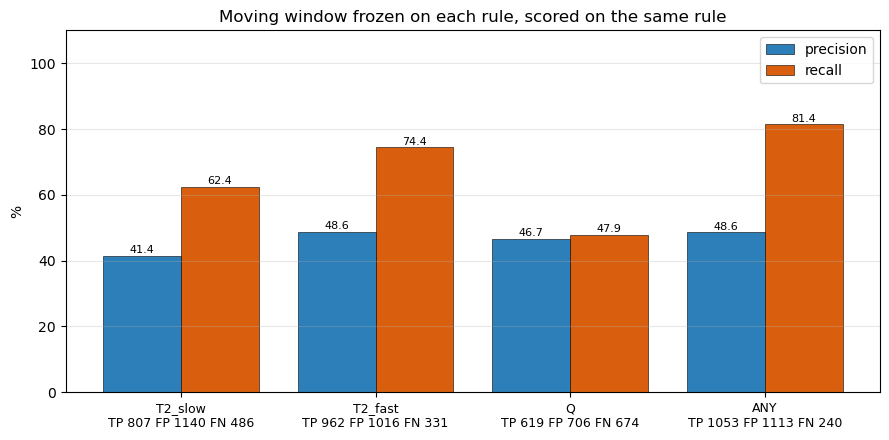

In [ ]:
def score_events(events, stats_df):
    t = stats_df[TS].to_numpy()
    n = len(t)
    valid = np.arange(n) >= NW
    days = valid.sum() / 1440      # 24 hours 60 minutes
    flags = {s: np.nan_to_num(stats_df[s].to_numpy(), nan=-np.inf)
                >= stats_df[f"{s}_limit"].to_numpy() for s in MONITOR}
    flags["ANY"] = np.logical_or.reduce([flags[s] for s in MONITOR])

    win = warning_windows(events)
    win["scored"] = win.usable & (win.w_start >= t[min(NW, n - 1)]) & (win.start <= t[-1])
    protect = np.zeros(n, bool)                   # [w_start, end]: never an FP
    in_flare = np.zeros(n, bool)                  # [start, end]:   ignored
    for w in win.itertuples(index=False):
        protect |= (t >= np.datetime64(w.w_start)) & (t <= np.datetime64(w.end))
        in_flare |= (t >= np.datetime64(w.start)) & (t <= np.datetime64(w.end))
    scored = win[win.scored]

    per_stat, per_event, fp_rows = [], scored[["event_id", "start", "end"]].copy(), []
    for rule, f in flags.items():
        f = f & valid
        ks, js = [], []
        for w in scored.itertuples(index=False):
            idx = np.flatnonzero((t >= np.datetime64(w.w_start)) & (t < np.datetime64(w.w_end)))
            hit = idx[f[idx]]
            ks.append(pd.Timestamp(t[hit[0]]) if len(hit) else pd.NaT)
            js.append((w.start - ks[-1]).total_seconds() / 60 if len(hit) else np.nan)
        per_event[f"{rule}_k"], per_event[f"{rule}_j_min"] = ks, js
        fp = runs(f & ~protect)
        fp_rows += [{"statistic": rule, "start": pd.Timestamp(t[a]),
                     "end": pd.Timestamp(t[b - 1]), "duration_min": b - a} for a, b in fp]
        tp = int(np.isfinite(js).sum())
        fn, n_fp = len(scored) - tp, len(fp)
        prec = tp / (tp + n_fp) if tp + n_fp else np.nan
        rec = tp / (tp + fn) if tp + fn else np.nan
        per_stat.append({
            "statistic": rule, "n_events": len(scored), "TP": tp, "FN": fn, "FP": n_fp,
            "precision_pct": 100 * prec, "recall_pct": 100 * rec})
    return pd.DataFrame(per_stat), per_event, pd.DataFrame(fp_rows)



# ---- precision / recall for every moving-window run --------------------------
# Each run gives its own statistics and limits, so each run is scored on all four
# alarm rules (T2_slow, T2_fast, Q, ANY). The "own rule" rows score a run on the
# same violation that drove its window.
parts = []
for rule, r in RUNS.items():
    sc, per_ev, fp = score_events(events, r["stats_df"])
    sc.insert(0, "freeze_rule", rule)
    r["score"], r["score_events_df"], r["fp_episodes"] = sc, per_ev, fp
    per_ev.to_csv(f"event_scoring_per_event_{rule}.csv", index=False)
    fp.to_csv(f"event_scoring_false_alarm_episodes_{rule}.csv", index=False)
    parts.append(sc)
score_all = pd.concat(parts, ignore_index=True)
score_all.to_csv("event_scoring_all_windows.csv", index=False)

print("All runs x all alarm rules:")
print(score_all.round(2).to_string(index=False))

own = score_all[score_all.freeze_rule == score_all.statistic].reset_index(drop=True)
own.to_csv("event_scoring_own_rule.csv", index=False)
print("\nEach run scored on its own violation rule:")
print(own.round(2).to_string(index=False))

for col in ("precision_pct", "recall_pct"):
    mat = score_all.pivot(index="freeze_rule", columns="statistic", values=col)
    mat = mat.reindex(index=list(RUNS), columns=list(MONITOR) + ["ANY"])
    print(f"\n{col}  (rows = freeze rule of the window, columns = alarm rule scored)")
    print(mat.round(2).to_string())

# grouped bars: precision and recall of each run on its own rule
fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(own))
for off, col, c in ((-0.2, "precision_pct", "#2c7fb8"), (0.2, "recall_pct", "#d95f0e")):
    b = ax.bar(x + off, own[col], 0.4, color=c, edgecolor="black", lw=0.4,
               label=col.replace("_pct", ""))
    for bar, v in zip(b, own[col]):
        if np.isfinite(v):
            ax.annotate(f"{v:.1f}", (bar.get_x() + bar.get_width() / 2, v), xytext=(0, 2),
                        textcoords="offset points", ha="center", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels([f"{r.freeze_rule}\nTP {r.TP} FP {r.FP} FN {r.FN}" for r in own.itertuples()],
                   fontsize=9)
ax.set_ylabel("%")
ax.set_ylim(0, 110)
ax.set_title("Moving window frozen on each rule, scored on the same rule")
ax.legend()
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig("precision_recall_all_windows.jpeg", dpi=200, bbox_inches="tight")
plt.show()

## 9. RBC root cause for one detected event - all moving-window runs
Taken at the detection instant with the model that was live then in each run. RBC
shares rank the tags; they do not add up to the statistic.

[T2_slow window]  807 detected events
event 2  T2_slow = 491.0 (limit 54.8), 60 min before onset
   ISOM::103TI5303B.daca.pv (2.197%), ISOM::103TI1667A.daca.pv (2.172%), ISOM::103TI5303A.daca.pv (2.143%), ISOM::103PI5301A.pv (1.92%), ISOM::103TI5608.daca.pv (1.879%)
event 3  T2_slow = 121.7 (limit 52.7), 60 min before onset
   DIU::71PI8703.PV (3.911%), DIU::71PC9101.PV (3.899%), DIU::71TI0405.PV (3.621%), DIU::71PI9902.PV (3.288%), DIU::71TI9702B.PV (3.237%)
event 4  T2_slow = 134.3 (limit 52.7), 60 min before onset
   DIU::71PC9101.PV (3.473%), DIU::71PI8703.PV (3.384%), DIU::71TI9702B.PV (3.022%), DIU::71TI0405.PV (2.866%), DIU::71PI9902.PV (2.744%)
event 5  T2_slow = 104.3 (limit 52.7), 42 min before onset
   DIU::71PC9101.PV (4.053%), DIU::71TI0405.PV (3.304%), DIU::71PI9902.PV (2.971%), DIU::71TI8403.PV (2.178%), PG::105TIC2215N.PV (1.701%)
event 6  T2_slow = 83.5 (limit 52.7), 60 min before onset
   CCR::102PI4767N.DACA.PV (2.36%), CCR::101PC1603B.DACA.PV (1.881%), SEU2::PTI3231

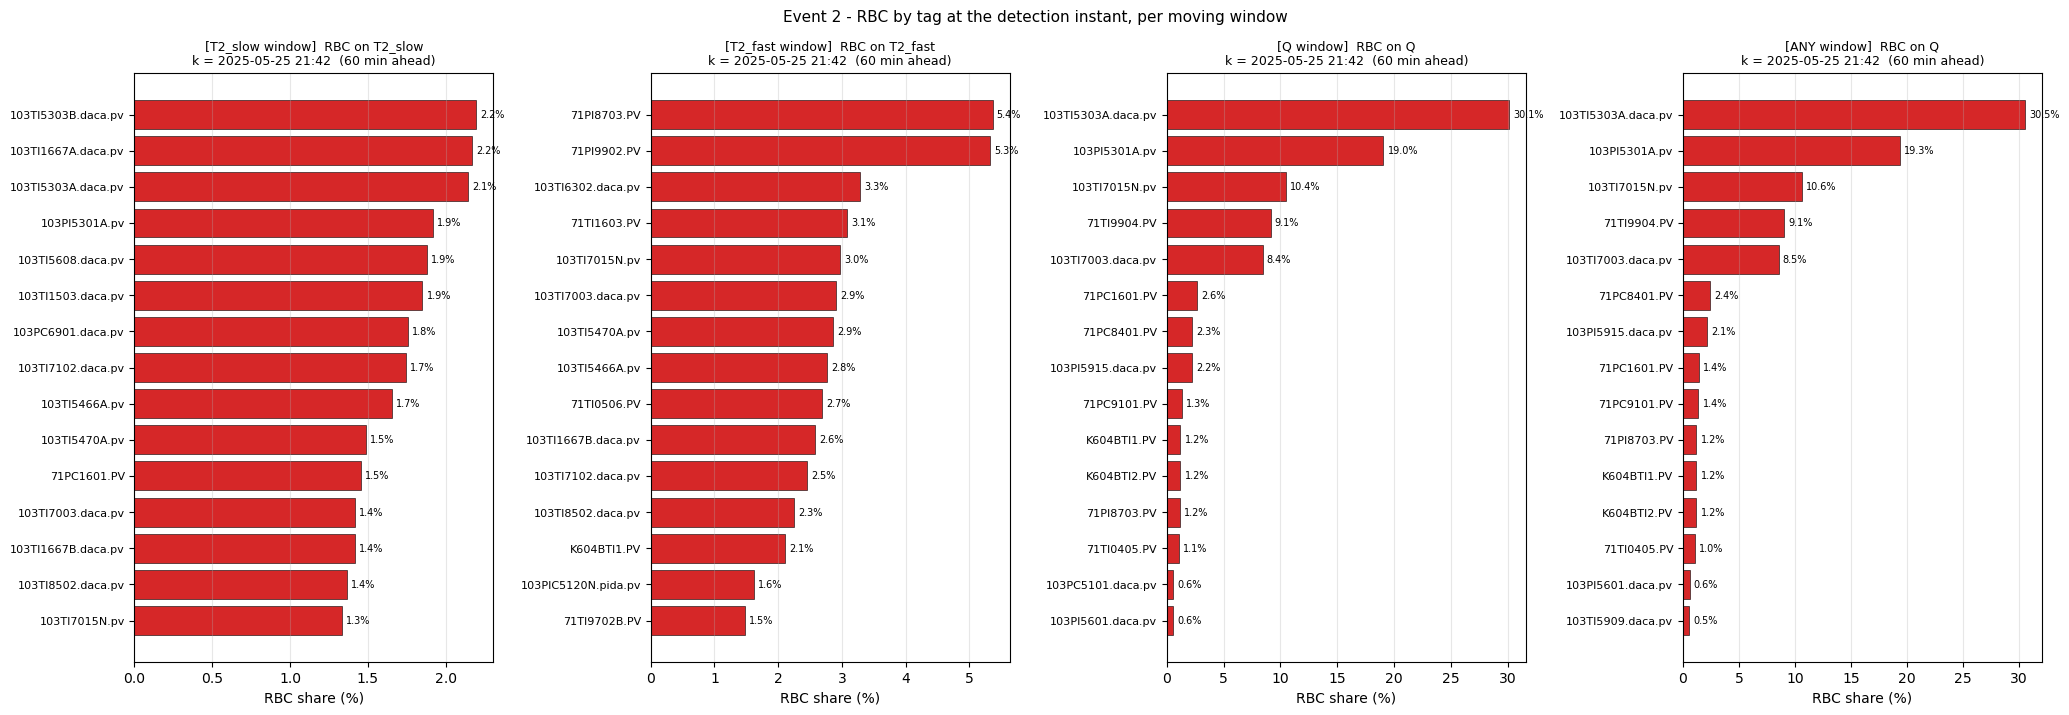

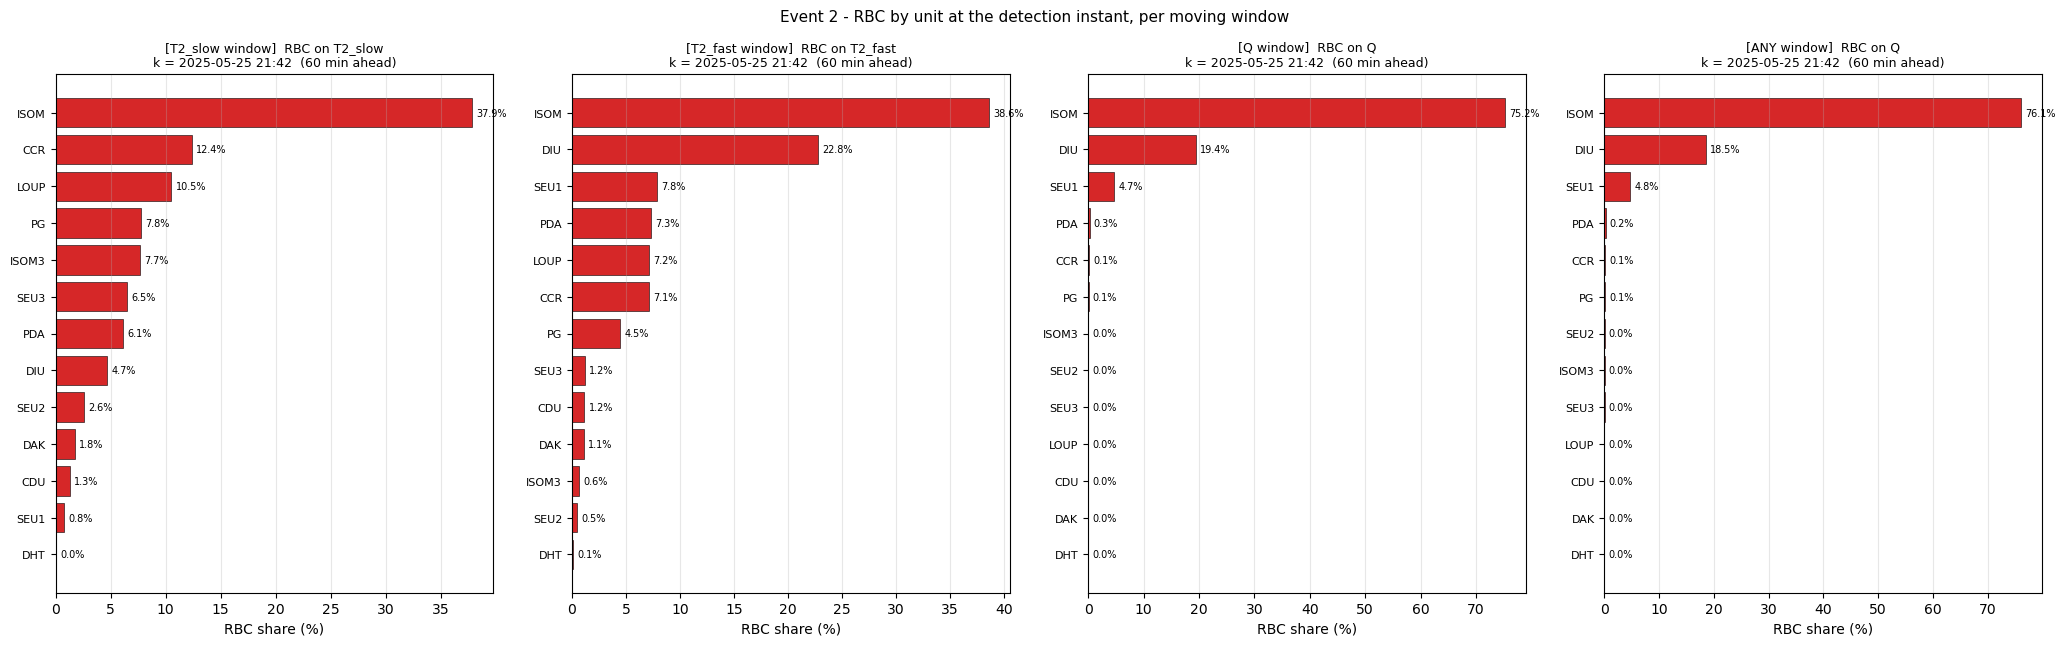

In [ ]:
EV = None      # event_id to plot; None -> first event detected by the most runs


def plot_event_rbc_all(eid, level="tags", top=15):
    """RBC at the detection instant of event eid, one panel per moving-window run."""
    rules = [r for r in RUNS if eid in RUNS[r]["event_rbc"]]
    if not rules:
        print(f"event {eid} was not detected by any run")
        return None
    name = "tag" if level == "tags" else "unit"
    n_rows = min(top, max(len(RUNS[r]["event_rbc"][eid][level]) for r in rules))
    fig, axs = plt.subplots(1, len(rules), figsize=(5.2 * len(rules), 0.35 * n_rows + 2),
                            squeeze=False)
    for ax, rule in zip(axs[0], rules):
        h = RUNS[rule]["event_rbc"][eid]
        df = h[level].head(top).iloc[::-1]
        ax.barh(range(len(df)), df.contrib_pct, color="#d62728", edgecolor="black", lw=0.4)
        ax.set_yticks(range(len(df)))
        ax.set_yticklabels([str(n).split("::")[-1] for n in df[name]], fontsize=8)
        for i, p in enumerate(df.contrib_pct):
            ax.annotate(f"{p:.1f}%", (p, i), xytext=(3, 0), textcoords="offset points",
                        va="center", fontsize=7)
        lead = (events.set_index("event_id").loc[eid, "start"] - h["time"]).total_seconds() / 60
        ax.set_title(f"[{rule} window]  RBC on {h['stat']}\n"
                     f"k = {h['time']:%Y-%m-%d %H:%M}  ({lead:.0f} min ahead)", fontsize=9)
        ax.set_xlabel("RBC share (%)")
        ax.grid(axis="x", alpha=0.3)
    fig.suptitle(f"Event {eid} - RBC by {name} at the detection instant, per moving window",
                 fontsize=11)
    fig.tight_layout()
    fig.savefig(f"rbc_event{eid}_{name}s_all_windows.jpeg", dpi=200, bbox_inches="tight")
    return fig


for rule, r in RUNS.items():
    det = r["event_df"][r["event_df"].detected]
    print("=" * 90)
    print(f"[{rule} window]  {len(det)} detected events")
    for row in det.head(10).itertuples(index=False):
        tags = ", ".join(f"{getattr(row, f'contrib_tag_{i}')} ({getattr(row, f'contrib_tag_{i}_pct')}%)"
                         for i in range(1, 6))
        print(f"event {row.event_id}  {row.detection_statistic} = {row.stat_value:.1f} "
              f"(limit {row.stat_limit:.1f}), {row.lead_min:.0f} min before onset\n   {tags}")

n_det = pd.Series({e: sum(e in r["event_rbc"] for r in RUNS.values()) for e in events.event_id})
if n_det.max() > 0:
    eid = int(n_det.idxmax()) if EV is None else int(EV)
    print(f"\nevent {eid}: detected by {n_det.get(eid, 0)} of {len(RUNS)} runs")
    plot_event_rbc_all(eid, "tags"); plt.show()
    plot_event_rbc_all(eid, "units", top=len(unit_names)); plt.show()

## 10. When was each flare predicted? - all moving-window runs
One bar per minute of warning time and per run; the last group counts flares with no warning.

 lead_min  T2_slow_n  T2_slow_cum_pct  T2_fast_n  T2_fast_cum_pct  Q_n  Q_cum_pct  ANY_n  ANY_cum_pct
       60        309            23.88        370            28.59  221      17.08    415        32.07
       59          7            24.42          5            28.98    6      17.54      6        32.53
       58          2            24.57          6            29.44    4      17.85      4        32.84
       57          3            24.81          6            29.91    2      18.01      8        33.46
       56          4            25.12          5            30.29    3      18.24      5        33.85
       55          3            25.35          4            30.60    2      18.39      3        34.08
       54          3            25.58          5            30.99    6      18.86      6        34.54
       53          3            25.81          8            31.61    6      19.32      7        35.09
       52          9            26.51         10            32.38    7      19.86 

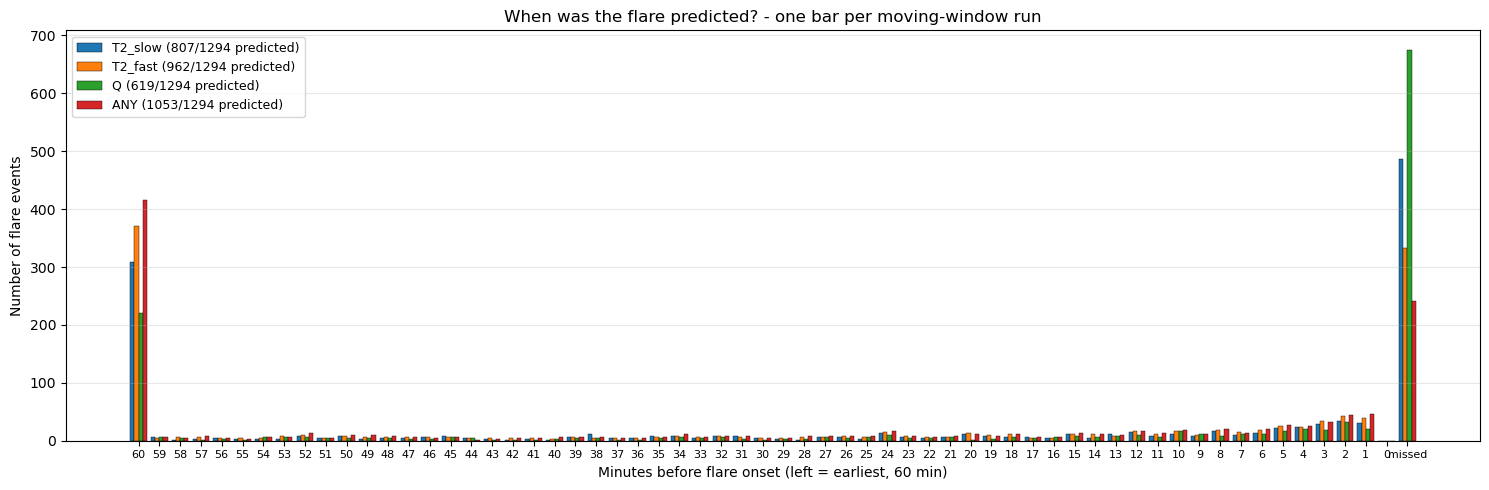

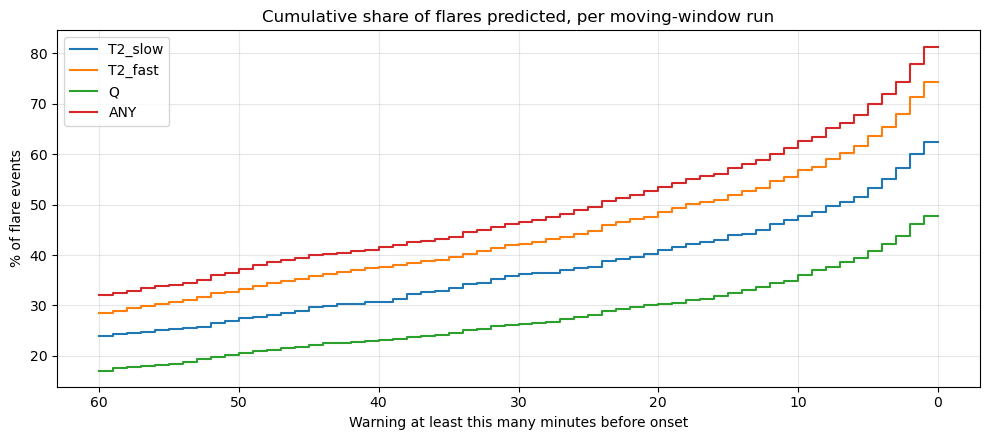

In [ ]:
def lead_time_table(event_df):
    leads = event_df.loc[event_df.detected, "lead_min"].to_numpy(float)
    b = np.clip(np.round(leads), 0, LEAD_MIN)
    tab = pd.DataFrame({"lead_min": np.arange(LEAD_MIN, -1, -1)})
    tab["n_events"] = [int((b == x).sum()) for x in tab.lead_min]
    tab["pct_of_events"] = (100 * tab.n_events / len(event_df)).round(2)
    tab["cumulative_pct"] = (100 * tab.n_events.cumsum() / len(event_df)).round(2)
    return tab


# ---- lead-time distribution for every moving-window run ----------------------
lead_all = pd.DataFrame({"lead_min": np.arange(LEAD_MIN, -1, -1)})
missed = {}
for rule, r in RUNS.items():
    tab = lead_time_table(r["event_df"])
    r["lead_tab"] = tab
    tab.to_csv(f"lead_time_distribution_{rule}.csv", index=False)
    lead_all[f"{rule}_n"] = tab.n_events.to_numpy()
    lead_all[f"{rule}_cum_pct"] = tab.cumulative_pct.to_numpy()
    missed[rule] = int((~r["event_df"].detected).sum())
lead_all.to_csv("lead_time_distribution_all_windows.csv", index=False)
print(lead_all[lead_all[[f"{r}_n" for r in RUNS]].sum(1) > 0].to_string(index=False))
n_ev = len(events)
print("\n" + "\n".join(f"[{r}] events {n_ev}, predicted {n_ev - m}, missed {m}"
                       for r, m in missed.items()))

labels = [str(x) for x in lead_all.lead_min] + ["missed"]
wid = 0.8 / len(RUNS)
fig, ax = plt.subplots(figsize=(15, 5))
for i, rule in enumerate(RUNS):
    h = list(lead_all[f"{rule}_n"]) + [missed[rule]]
    ax.bar(np.arange(len(labels)) - 0.4 + wid * (i + 0.5), h, wid, edgecolor="black", lw=0.3,
           label=f"{rule} ({n_ev - missed[rule]}/{n_ev} predicted)")
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels, fontsize=8)
ax.set_xlabel(f"Minutes before flare onset (left = earliest, {LEAD_MIN} min)")
ax.set_ylabel("Number of flare events")
ax.set_title("When was the flare predicted? - one bar per moving-window run")
ax.legend(fontsize=9)
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig("lead_time_distribution_all_windows.jpeg", dpi=200, bbox_inches="tight")
plt.show()

# cumulative share of events predicted at least x min ahead
fig, ax = plt.subplots(figsize=(10, 4.5))
for rule in RUNS:
    ax.step(lead_all.lead_min, lead_all[f"{rule}_cum_pct"], where="post", label=rule)
ax.invert_xaxis()
ax.set_xlabel("Warning at least this many minutes before onset")
ax.set_ylabel("% of flare events")
ax.set_title("Cumulative share of flares predicted, per moving-window run")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("lead_time_cumulative_all_windows.jpeg", dpi=200, bbox_inches="tight")
plt.show()

## 11. Plotting functions for one event
* `plot_stats_tags_flare` - the active run's statistic(s) only (`RUN_STATS`: T2_slow
  for the T2_slow window, ...; all three for ANY) with limits and alarms, chosen raw
  tags, and the flare flow on one time axis. Green =
  warning window, orange = flare, dashed green = detection.
* `plot_rbc_instants` - RBC at the detection instant *k* and at the fixed
  offsets from the flare start: bar chart per instant, and heat maps of the
  tag and unit shares over the instants. Frozen tags are left out of the bars;
  their share is printed on each panel.

In [ ]:
def resolve_tag(name):
    """'CDU::41PI41121.pv' or just '41PI41121.pv' -> the column name."""
    if name in tag_names:
        return name
    hits = [c for c in tag_names if name.split("::")[-1].lower() in c.lower()]
    if len(hits) != 1:
        raise KeyError(f"tag {name!r}: {len(hits)} matches {hits[:10]}")
    return hits[0]


def plot_stats_tags_flare(start, end, tags=(), savepath=None):
    tags = [resolve_tag(t) for t in tags]
    s = stats_df[(stats_df[TS] >= start) & (stats_df[TS] <= end)]
    a = All_df[(All_df[TS] >= start) & (All_df[TS] <= end)]
    f = flare_df[(flare_df[TS] >= start) & (flare_df[TS] <= end)]
    n = len(RUN_STATS) + len(tags) + 1
    fig, axes = plt.subplots(n, 1, figsize=(15, 2.6 * n), sharex=True)
    for ax, key in zip(axes, RUN_STATS):
        v, lim = s[key].to_numpy(), s[f"{key}_limit"].to_numpy()
        ax.plot(s[TS], v, lw=0.8, label=key)
        ax.plot(s[TS], lim, "r--", lw=1.1, label="control limit")
        exc = v >= lim
        ax.scatter(s[TS][exc], v[exc], s=6, c="red", zorder=3, label="alarm")
        ax.set_ylabel(key)
        ax.legend(loc="upper left", fontsize=7.5, ncol=3)
    for n_t, (ax, tag) in enumerate(zip(axes[len(RUN_STATS):], tags), 1):
        ax.plot(a[TS], a[tag], lw=0.8, color="#2ca02c")
        ax.set_ylabel(f"#{n_t} " + tag.split("::")[-1], fontsize=8.5)
        ax.set_title(tag, fontsize=8.5, loc="left")
    axes[-1].plot(f[TS], f[FLOW], lw=0.8, color="#8c564b", label="flare flowrate")
    axes[-1].axhline(THRESHOLD, color="red", ls="--", lw=1.2, label=f"{THRESHOLD} MT/h")
    axes[-1].set_ylabel("Flare (MT/h)")
    axes[-1].legend(loc="upper left", fontsize=7.5)

    ev = event_df[(event_df.event_end >= start) & (event_df.event_start <= end)]
    wv = windows[windows.usable & (windows.w_end >= start) & (windows.w_start <= end)]
    for ax in axes:
        ax.grid(alpha=0.3)
        for w in wv.itertuples(index=False):
            ax.axvspan(max(w.w_start, start), min(w.w_end, end), color="green", alpha=0.18, lw=0)
        for e in ev.itertuples(index=False):
            ax.axvspan(max(e.event_start, start), min(e.event_end, end), color="orange", alpha=0.2, lw=0)
            if e.detected and start <= e.detection_time <= end:
                ax.axvline(e.detection_time, color="green", ls="--", lw=1.3)
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d-%b %H:%M"))
    fig.autofmt_xdate(rotation=30)
    axes[0].set_title(f"[{ACTIVE_RULE} window] {start:%Y-%m-%d %H:%M} to {end:%Y-%m-%d %H:%M}   {'+'.join(RUN_STATS)} "
                      f"+ {len(tags)} tag(s) + flare   [{len(ev)} event(s)]", fontsize=10)
    fig.tight_layout()
    if savepath:
        fig.savefig(savepath, dpi=200, bbox_inches="tight")
    return fig


def snapshot_tables(row):
    """Tag and unit RBC share tables of one stored snapshot (frozen tags removed)."""
    v, flat = row.rbc, row.flat
    ok = np.isfinite(v)
    tot = max(np.nansum(v), EPS)
    tag = pd.DataFrame({"tag": np.array(tag_names)[ok],
                        "unit": np.array([unit_names[u] for u in unit_of_col])[ok],
                        "pct": 100 * v[ok] / tot, "flat": flat[ok]})
    flat_pct = tag.loc[tag.flat, "pct"].sum()
    tag = tag[~tag.flat].sort_values("pct", ascending=False)
    unit = tag.groupby("unit")["pct"].sum()
    unit = 100 * unit / max(unit.sum(), EPS)
    return tag, unit, flat_pct


def detection_stat(eid):
    """The statistic that detected the event, else the one furthest above its limit."""
    if eid in event_rbc:
        return event_rbc[eid]["stat"]
    s = snaps[snaps.event_id == eid]
    return s.groupby("stat").ratio.max().idxmax()


def plot_rbc_instants(eid, top=10, heat_top=15, savepath=None):
    stat = detection_stat(eid)
    sn = snaps[(snaps.event_id == eid) & (snaps.stat == stat)]
    sn = sn.sort_values(["offset_min", "is_k"]).reset_index(drop=True)
    e = events.set_index("event_id").loc[eid]
    tabs = [snapshot_tables(r) for r in sn.itertuples(index=False)]
    cols = [f"{r.label}\n{r.time:%H:%M}" for r in sn.itertuples(index=False)]

    # ---- bar chart per instant ----
    ucol = {u: plt.get_cmap("tab20")(i % 20) for i, u in enumerate(unit_names)}
    nc = min(4, len(sn))
    nr = int(np.ceil(len(sn) / nc))
    fig, axs = plt.subplots(nr, nc, figsize=(4.3 * nc, 3.2 * nr + 0.8), squeeze=False)
    for ax in axs.ravel()[len(sn):]:
        ax.axis("off")
    for ax, r, (tag, unit, fp) in zip(axs.ravel(), sn.itertuples(index=False), tabs):
        d = tag.head(top).iloc[::-1]
        ax.barh(range(len(d)), d.pct, color=[ucol[u] for u in d.unit],
                edgecolor="black", lw=0.3)
        ax.set_yticks(range(len(d)))
        ax.set_yticklabels([t.split("::")[-1] for t in d.tag], fontsize=7)
        ax.tick_params(axis="x", labelsize=7)
        ax.set_xlabel("RBC share (%)", fontsize=7)
        ax.grid(axis="x", alpha=0.3)
        ttl = (f"{r.label} ({r.time:%H:%M})\n{stat}/limit = {r.ratio:.2f} "
               f"[{'ALARM' if r.ratio >= 1 else 'no alarm'}]")
        if fp > 1:
            ttl += f"\nfrozen tags hidden: {fp:.0f}%"
        ax.set_title(ttl, fontsize=8, color="green" if r.is_k else "black")
    used = sorted({u for tag, _, _ in tabs for u in tag.head(top).unit})
    fig.legend(handles=[Patch(color=ucol[u], label=u) for u in used], loc="lower center",
               ncol=min(len(used), 8), fontsize=8, frameon=False)
    fig.suptitle(f"[{ACTIVE_RULE} window] Event {eid}  start {e.start:%Y-%m-%d %H:%M}  RBC on {stat}", fontsize=10)
    fig.tight_layout(rect=(0, 0.05, 1, 0.97))
    if savepath:
        fig.savefig(savepath, dpi=200, bbox_inches="tight")

    # ---- heat maps over the instants ----
    best = {}
    for tag, _, _ in tabs:
        for t, p in zip(tag.tag.head(5), tag.pct.head(5)):
            best[t] = max(best.get(t, 0), p)
    heat = sorted(best, key=best.get, reverse=True)[:heat_top]
    tag_mat = pd.DataFrame({c: t.set_index("tag").pct.reindex(heat)
                            for c, (t, _, _) in zip(cols, tabs)})
    unit_mat = pd.DataFrame({c: u for c, (_, u, _) in zip(cols, tabs)}).fillna(0)
    unit_mat = unit_mat.loc[unit_mat.mean(1).sort_values(ascending=False).index]
    fig2, (a1, a2) = plt.subplots(1, 2, figsize=(max(12, 1.2 * len(cols) + 7),
                                                 0.38 * max(len(tag_mat), 8) + 2))
    for ax, mat, name in ((a1, tag_mat, "tag"), (a2, unit_mat, "unit")):
        vals = mat.to_numpy(float)
        im = ax.imshow(np.nan_to_num(vals), aspect="auto", cmap="Reds", vmin=0)
        ax.set_xticks(range(mat.shape[1]))
        ax.set_xticklabels(mat.columns, fontsize=7)
        ax.set_yticks(range(mat.shape[0]))
        ax.set_yticklabels([str(x).split("::")[-1] for x in mat.index], fontsize=7)
        for (y, x), v in np.ndenumerate(vals):
            if v == v and v >= 0.5:
                ax.text(x, y, f"{v:.0f}", ha="center", va="center", fontsize=6.5)
        ax.set_title(f"RBC share (%) by {name}", fontsize=9)
        fig2.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
    fig2.suptitle(f"Event {eid} - RBC on {stat} at each instant "
                  f"(k = detection, offsets from flare start)", fontsize=10)
    fig2.tight_layout()
    if savepath:
        fig2.savefig(savepath.replace(".jpeg", "_heatmap.jpeg"), dpi=200, bbox_inches="tight")
    return fig, fig2, tag_mat, unit_mat

## 12. Per event: run statistic + top 3 tags + flare, then RBC at the time instants
Drawn for every run in `PLOT_RULES`. For each event and run: (i) one figure with the run's
own statistic (T2_slow only for the T2_slow window, T2_fast only for T2_fast, Q only for Q,
all three for ANY), the top 3 RBC tags and the flare flowrate; (ii) RBC bars and
(iii) heat maps over the instants, on that statistic only. The last part of the section
counts the top RBC tags / units per run and compares the runs side by side.

##########################################################################################
MOVING WINDOW [T2_slow]  hold on T2_slow
[T2_slow] EVENT 1000  start 2026-02-02 11:00  peak 4.01 MT/h  detected 38 min ahead by T2_slow
tags: CCR::508PC5103.DACA.PV, SEU1::02TC205W.PV, CCR::102PI4767N.DACA.PV


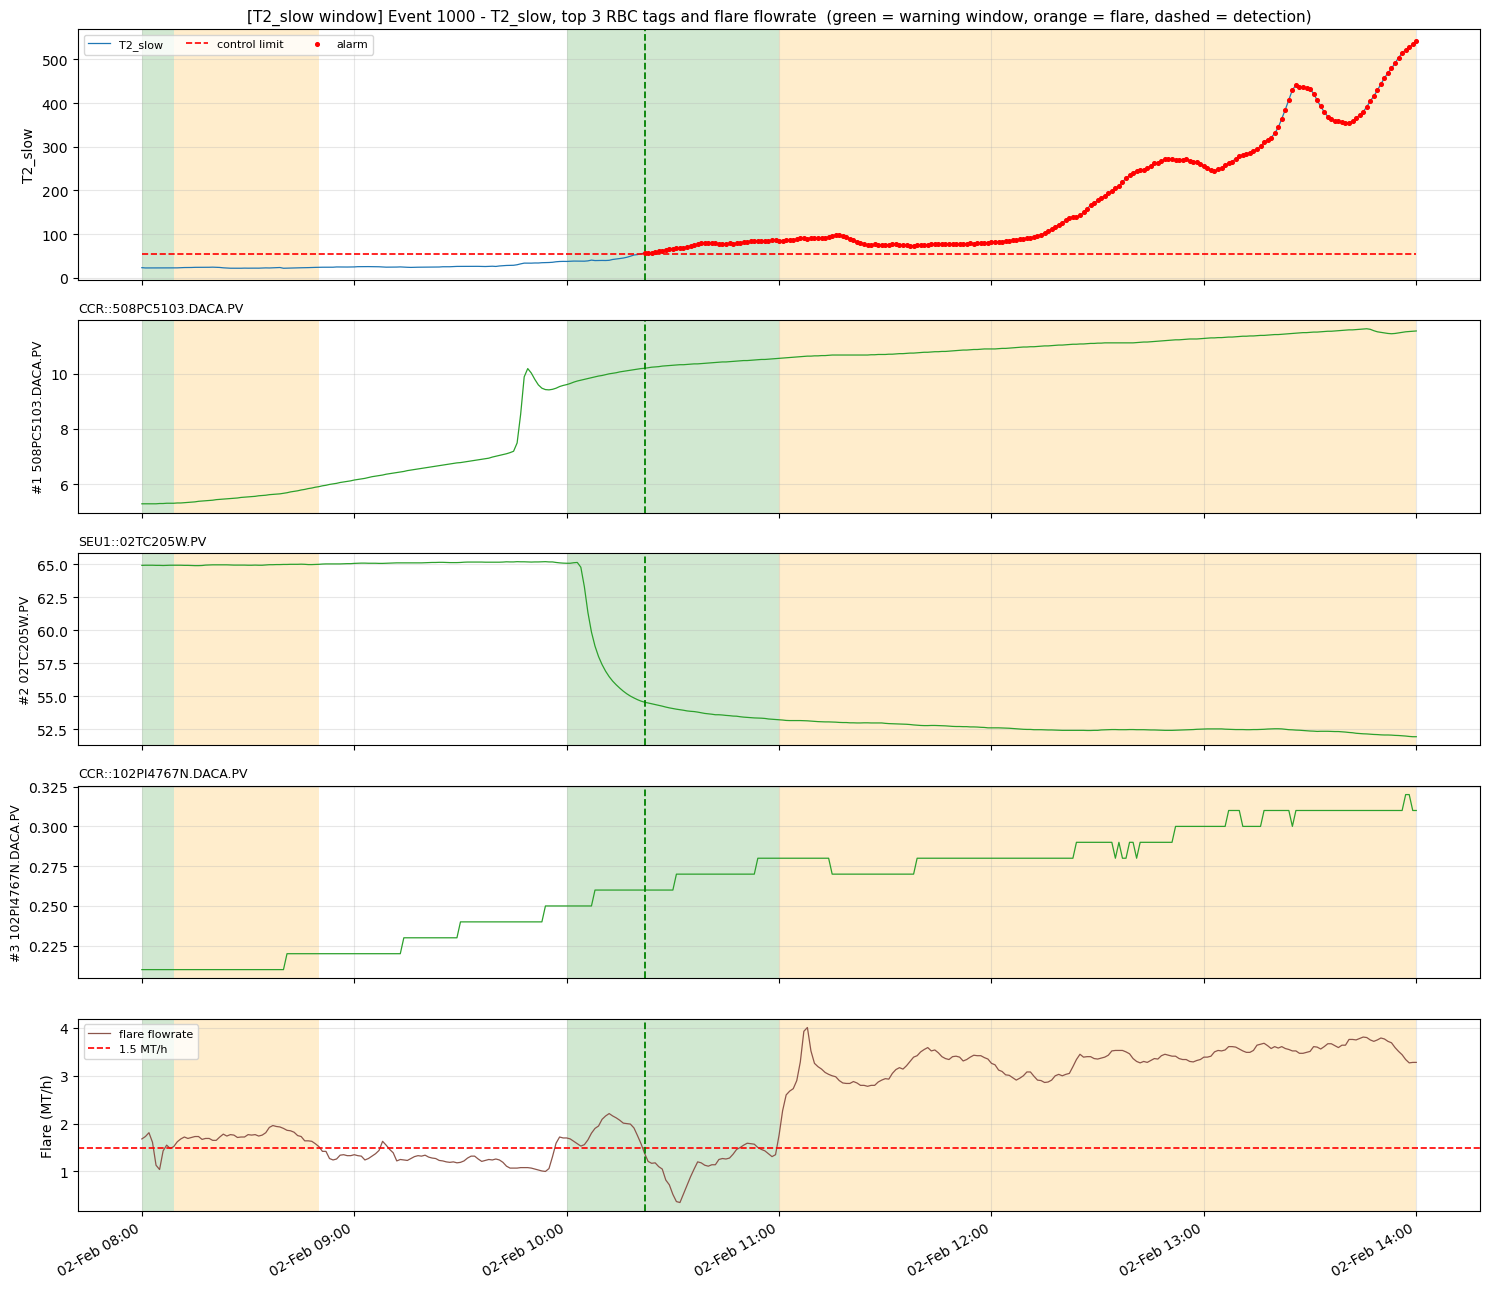

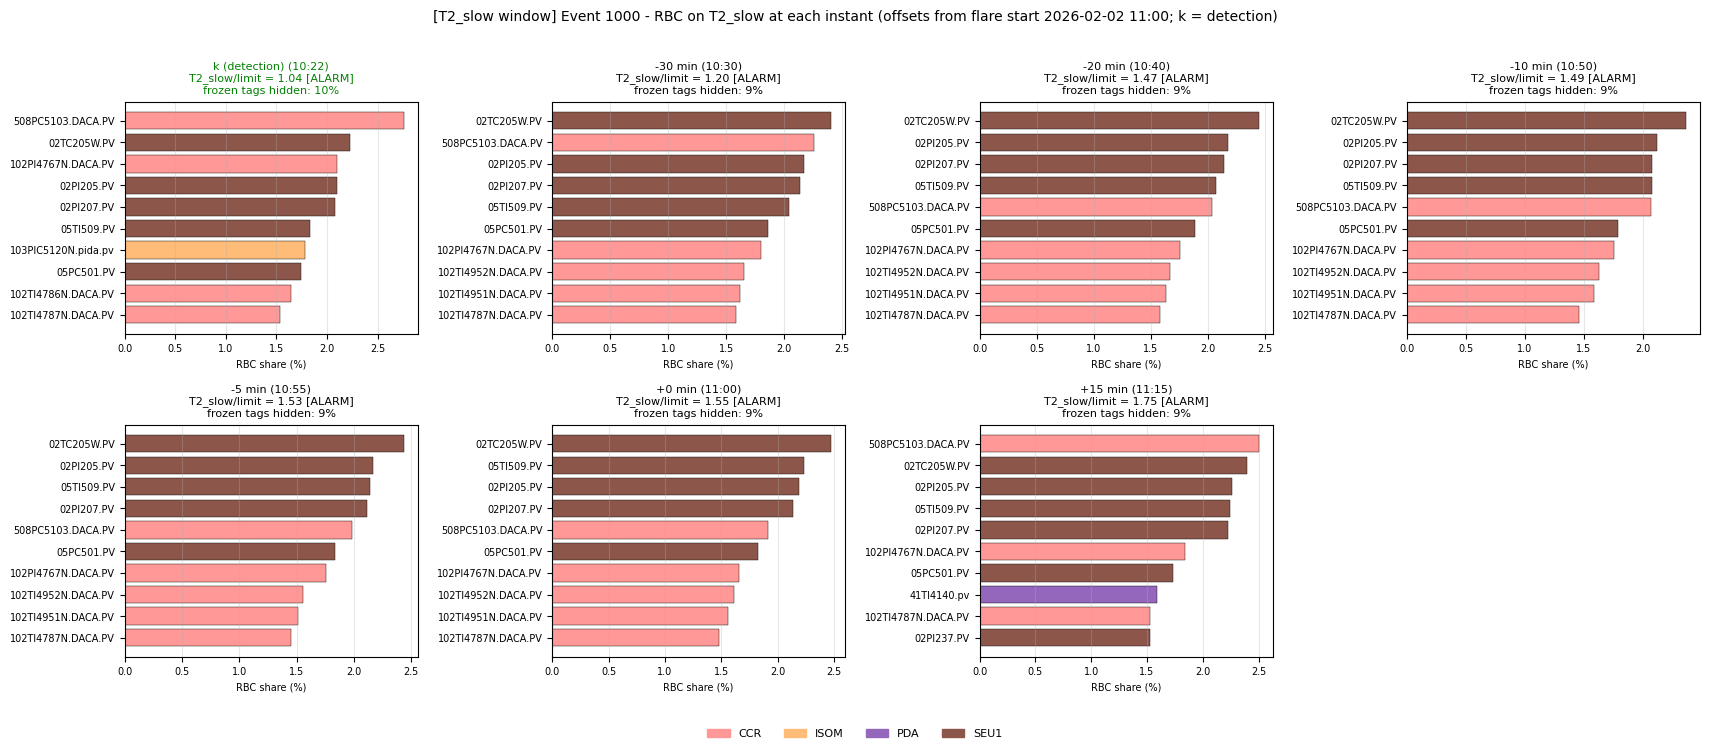

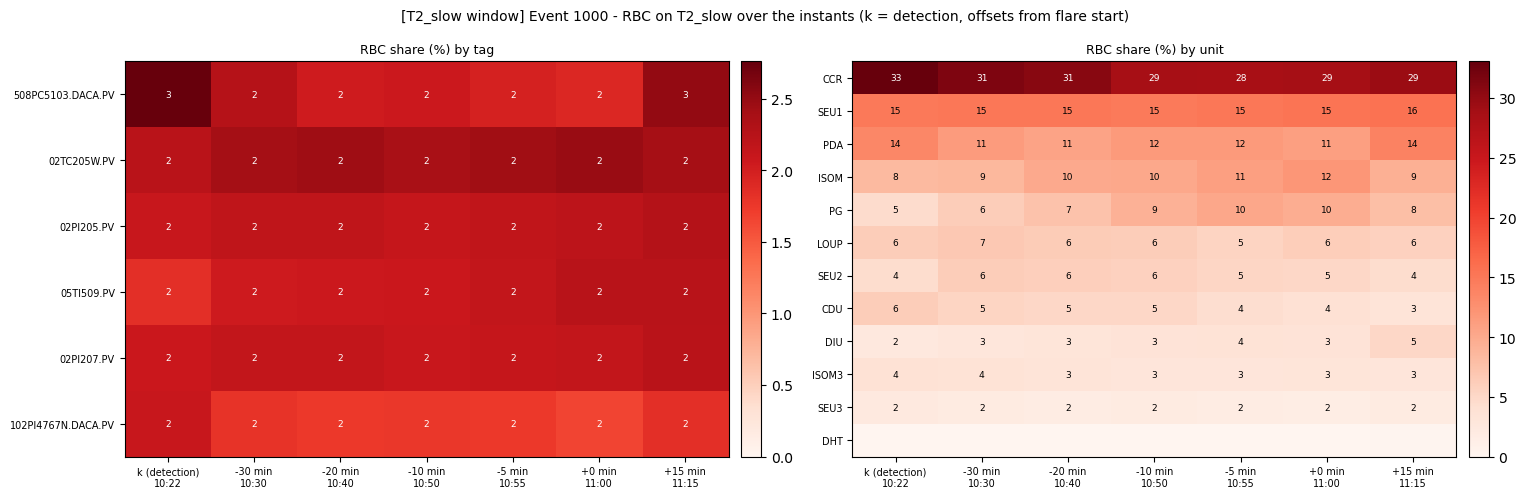

                         k (detection) @ 10:22  -30 min @ 10:30  -20 min @ 10:40  -10 min @ 10:50  -5 min @ 10:55  +0 min @ 11:00  +15 min @ 11:15
tag                                                                                                                                               
CCR::508PC5103.DACA.PV                     2.8              2.3              2.0              2.1             2.0             1.9              2.5
SEU1::02TC205W.PV                          2.2              2.4              2.4              2.4             2.4             2.5              2.4
SEU1::02PI205.PV                           2.1              2.2              2.2              2.1             2.2             2.2              2.3
SEU1::05TI509.PV                           1.8              2.0              2.1              2.1             2.1             2.2              2.2
SEU1::02PI207.PV                           2.1              2.1              2.1              2.1             2.1     

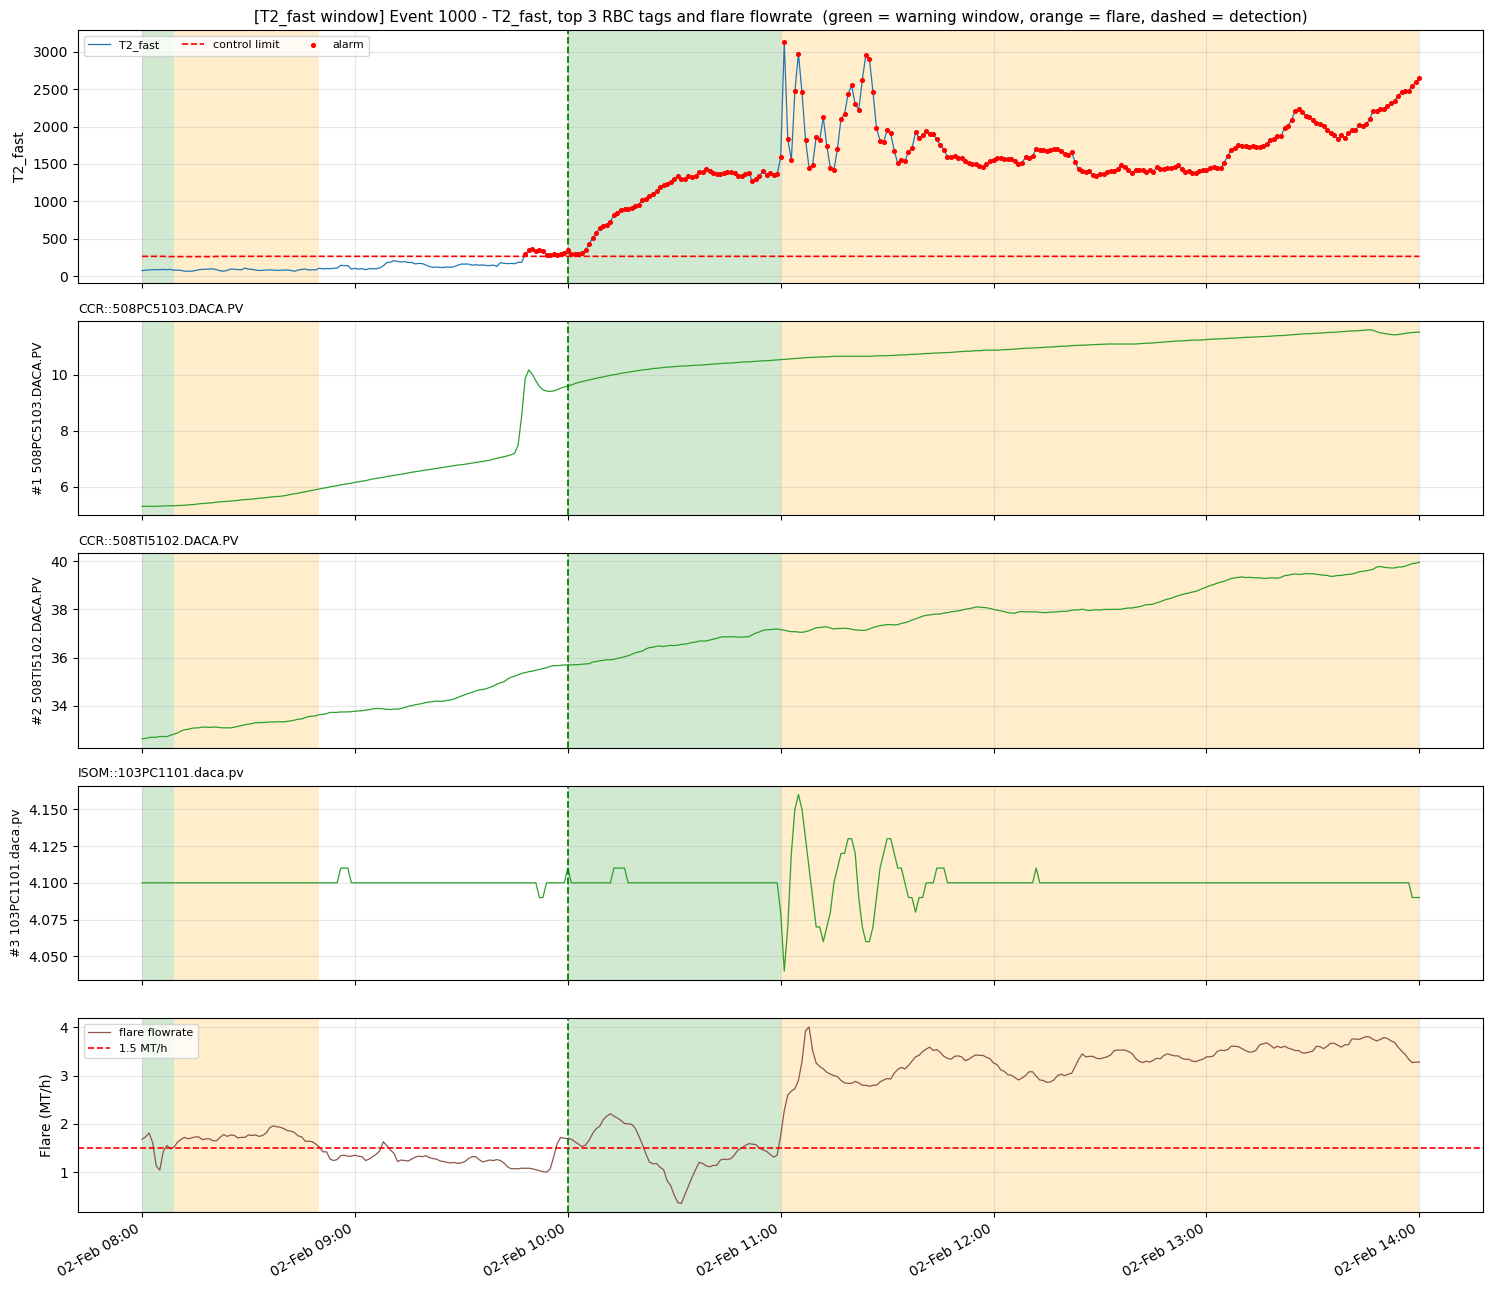

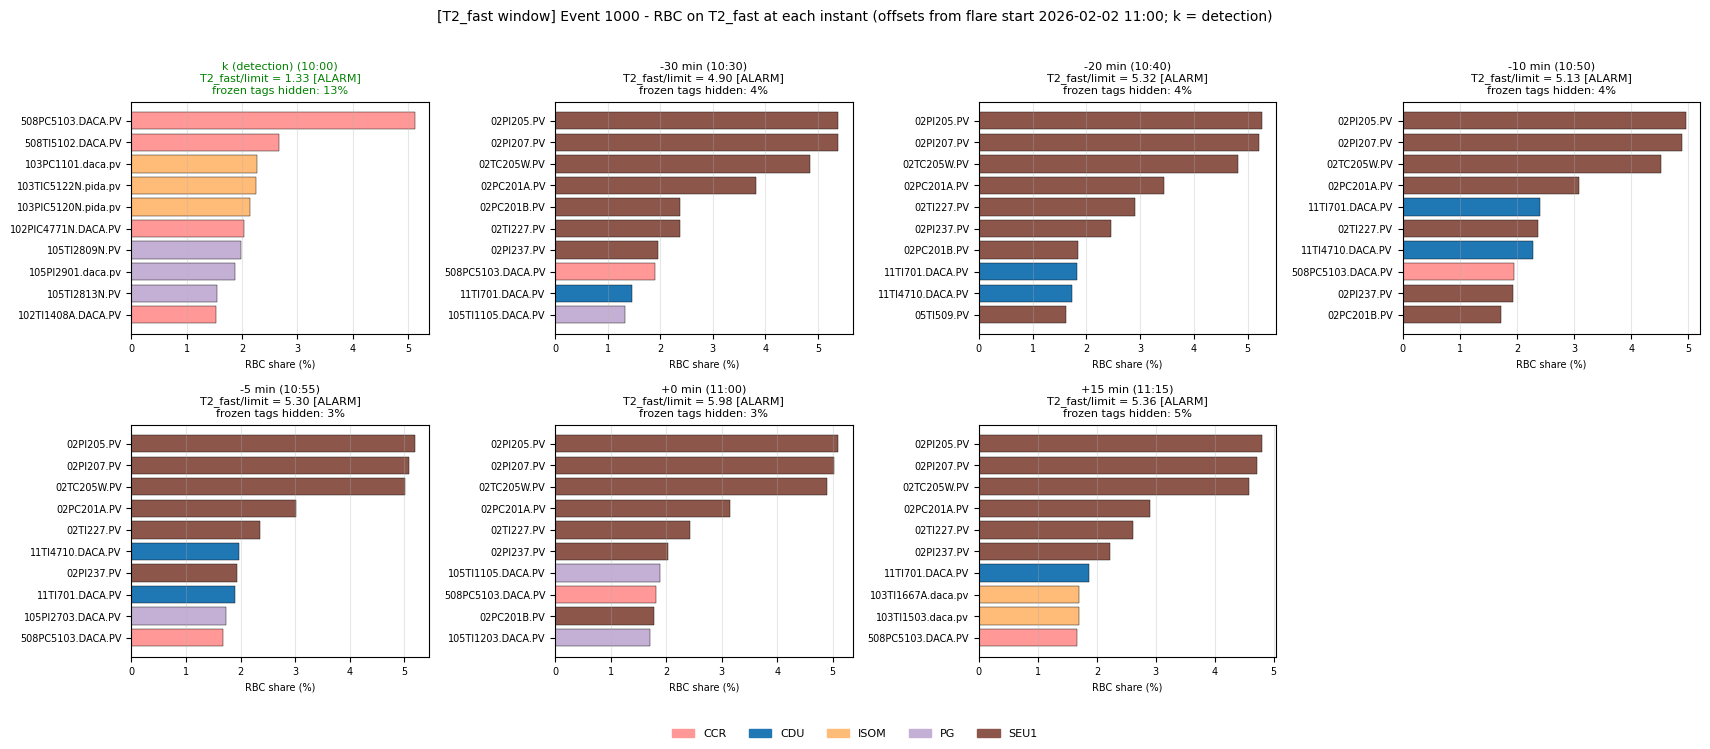

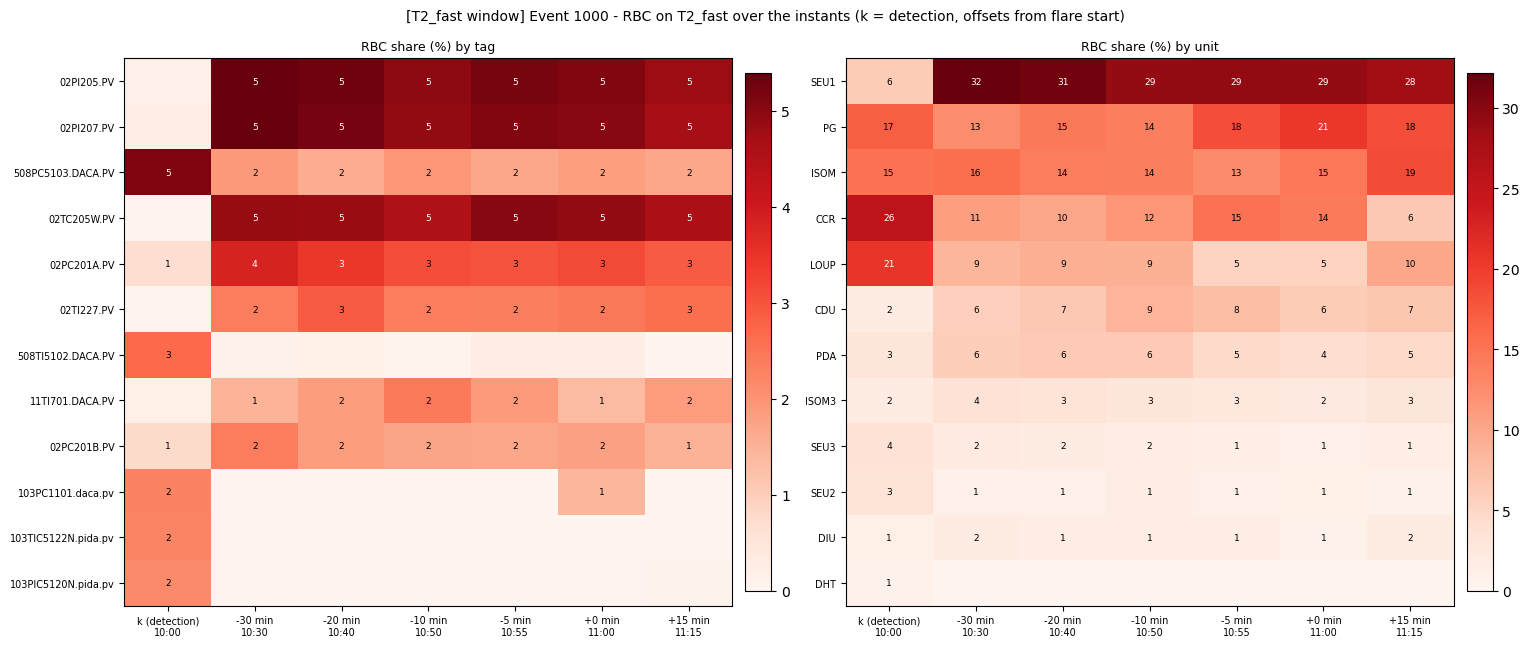

                           k (detection) @ 10:00  -30 min @ 10:30  -20 min @ 10:40  -10 min @ 10:50  -5 min @ 10:55  +0 min @ 11:00  +15 min @ 11:15
tag                                                                                                                                                 
SEU1::02PI205.PV                             0.2              5.4              5.3              5.0             5.2             5.1              4.8
SEU1::02PI207.PV                             0.2              5.4              5.2              4.9             5.1             5.0              4.7
CCR::508PC5103.DACA.PV                       5.1              1.9              1.6              1.9             1.7             1.8              1.7
SEU1::02TC205W.PV                            0.0              4.8              4.8              4.5             5.0             4.9              4.6
SEU1::02PC201A.PV                            0.7              3.8              3.5              3.1       

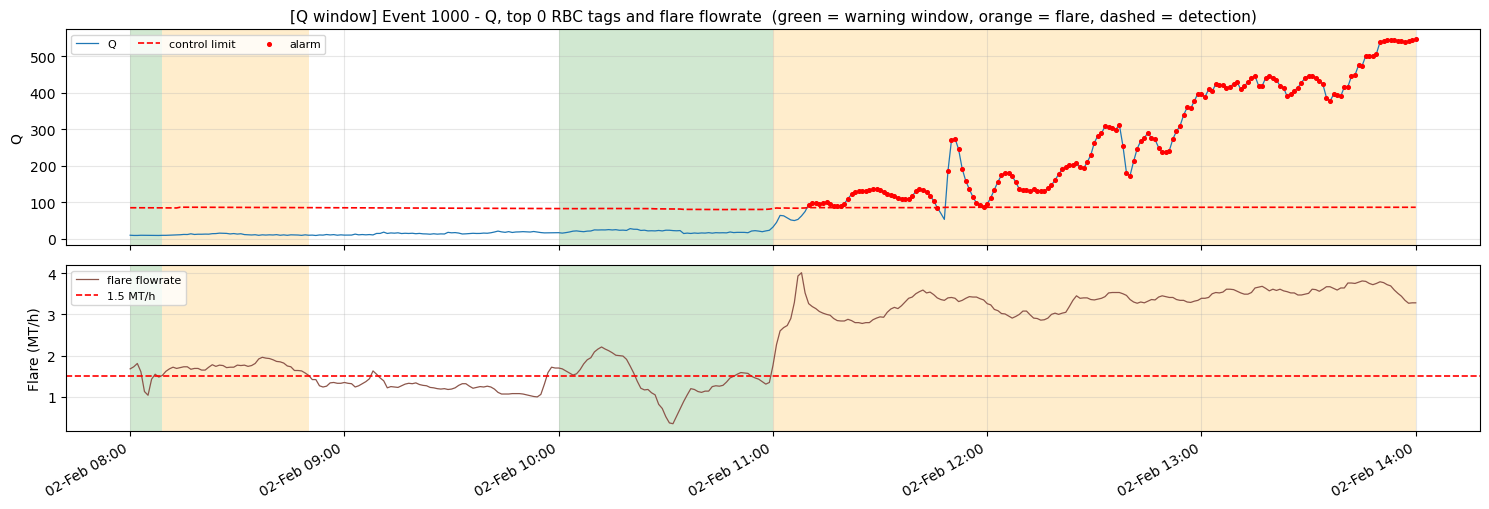

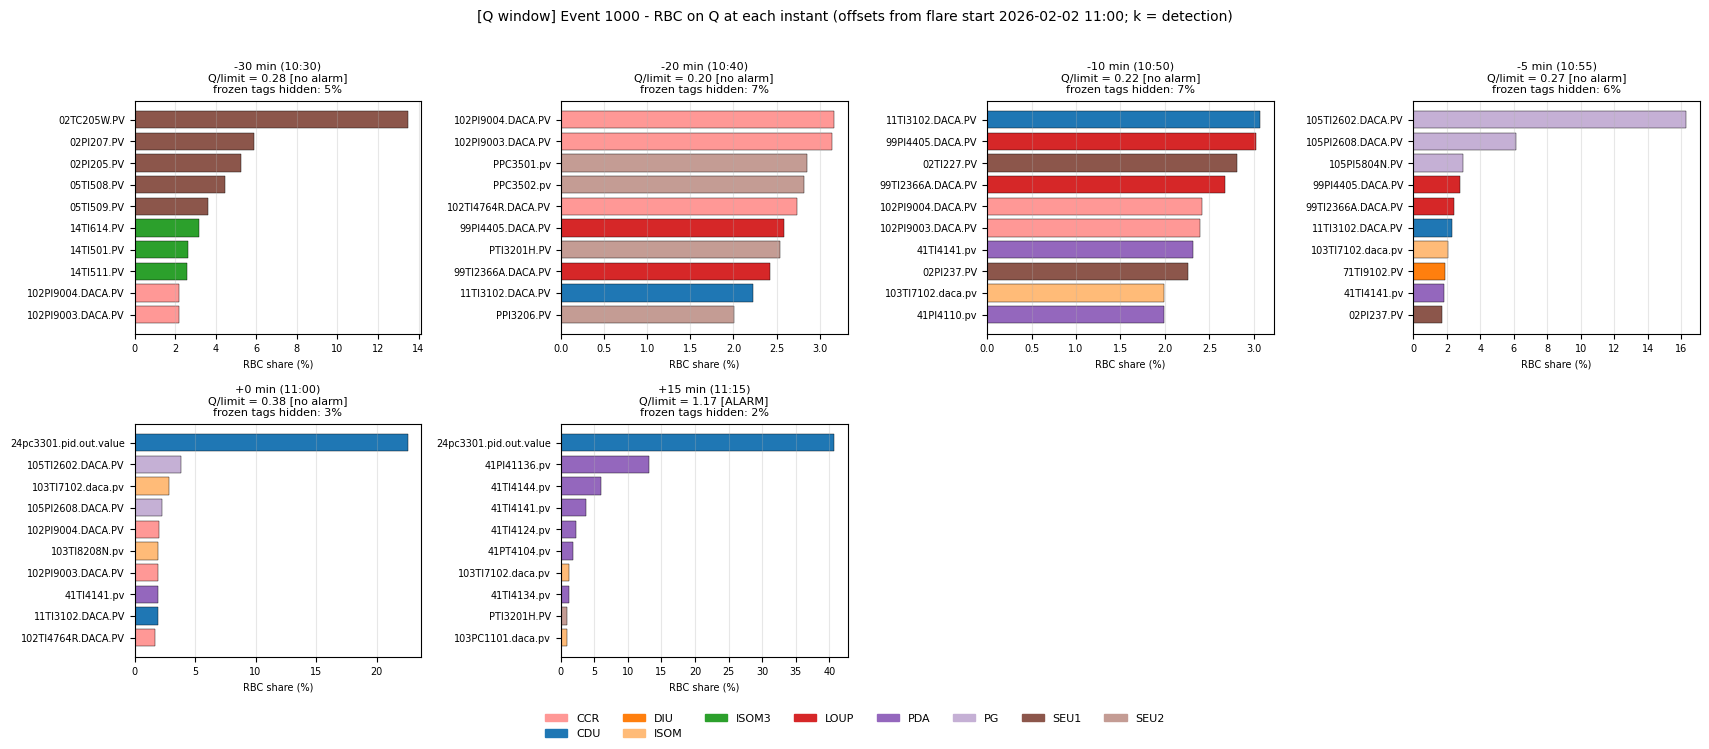

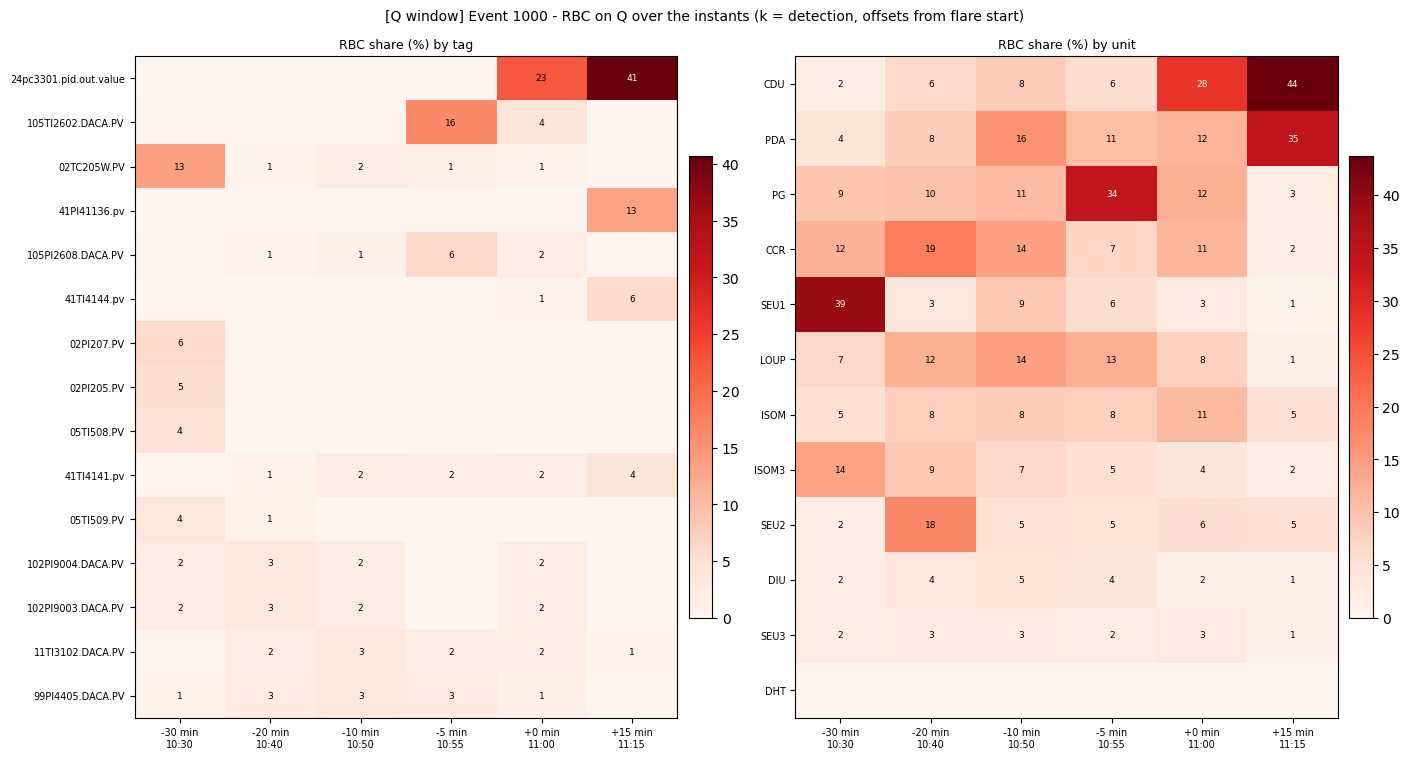

                             -30 min @ 10:30  -20 min @ 10:40  -10 min @ 10:50  -5 min @ 10:55  +0 min @ 11:00  +15 min @ 11:15
tag                                                                                                                            
CDU::24pc3301.pid.out.value              NaN              NaN              NaN             NaN            22.6             40.7
PG::105TI2602.DACA.PV                    0.2              0.3              0.4            16.3             3.9              0.1
SEU1::02TC205W.PV                       13.5              0.7              1.8             1.3             0.7              0.1
PDA::41PI41136.pv                        0.0              0.2              0.1             0.1             0.1             13.1
PG::105PI2608.DACA.PV                    0.4              0.8              1.2             6.1             2.3              0.3
PDA::41TI4144.pv                         0.0              0.1              0.0             0.2          

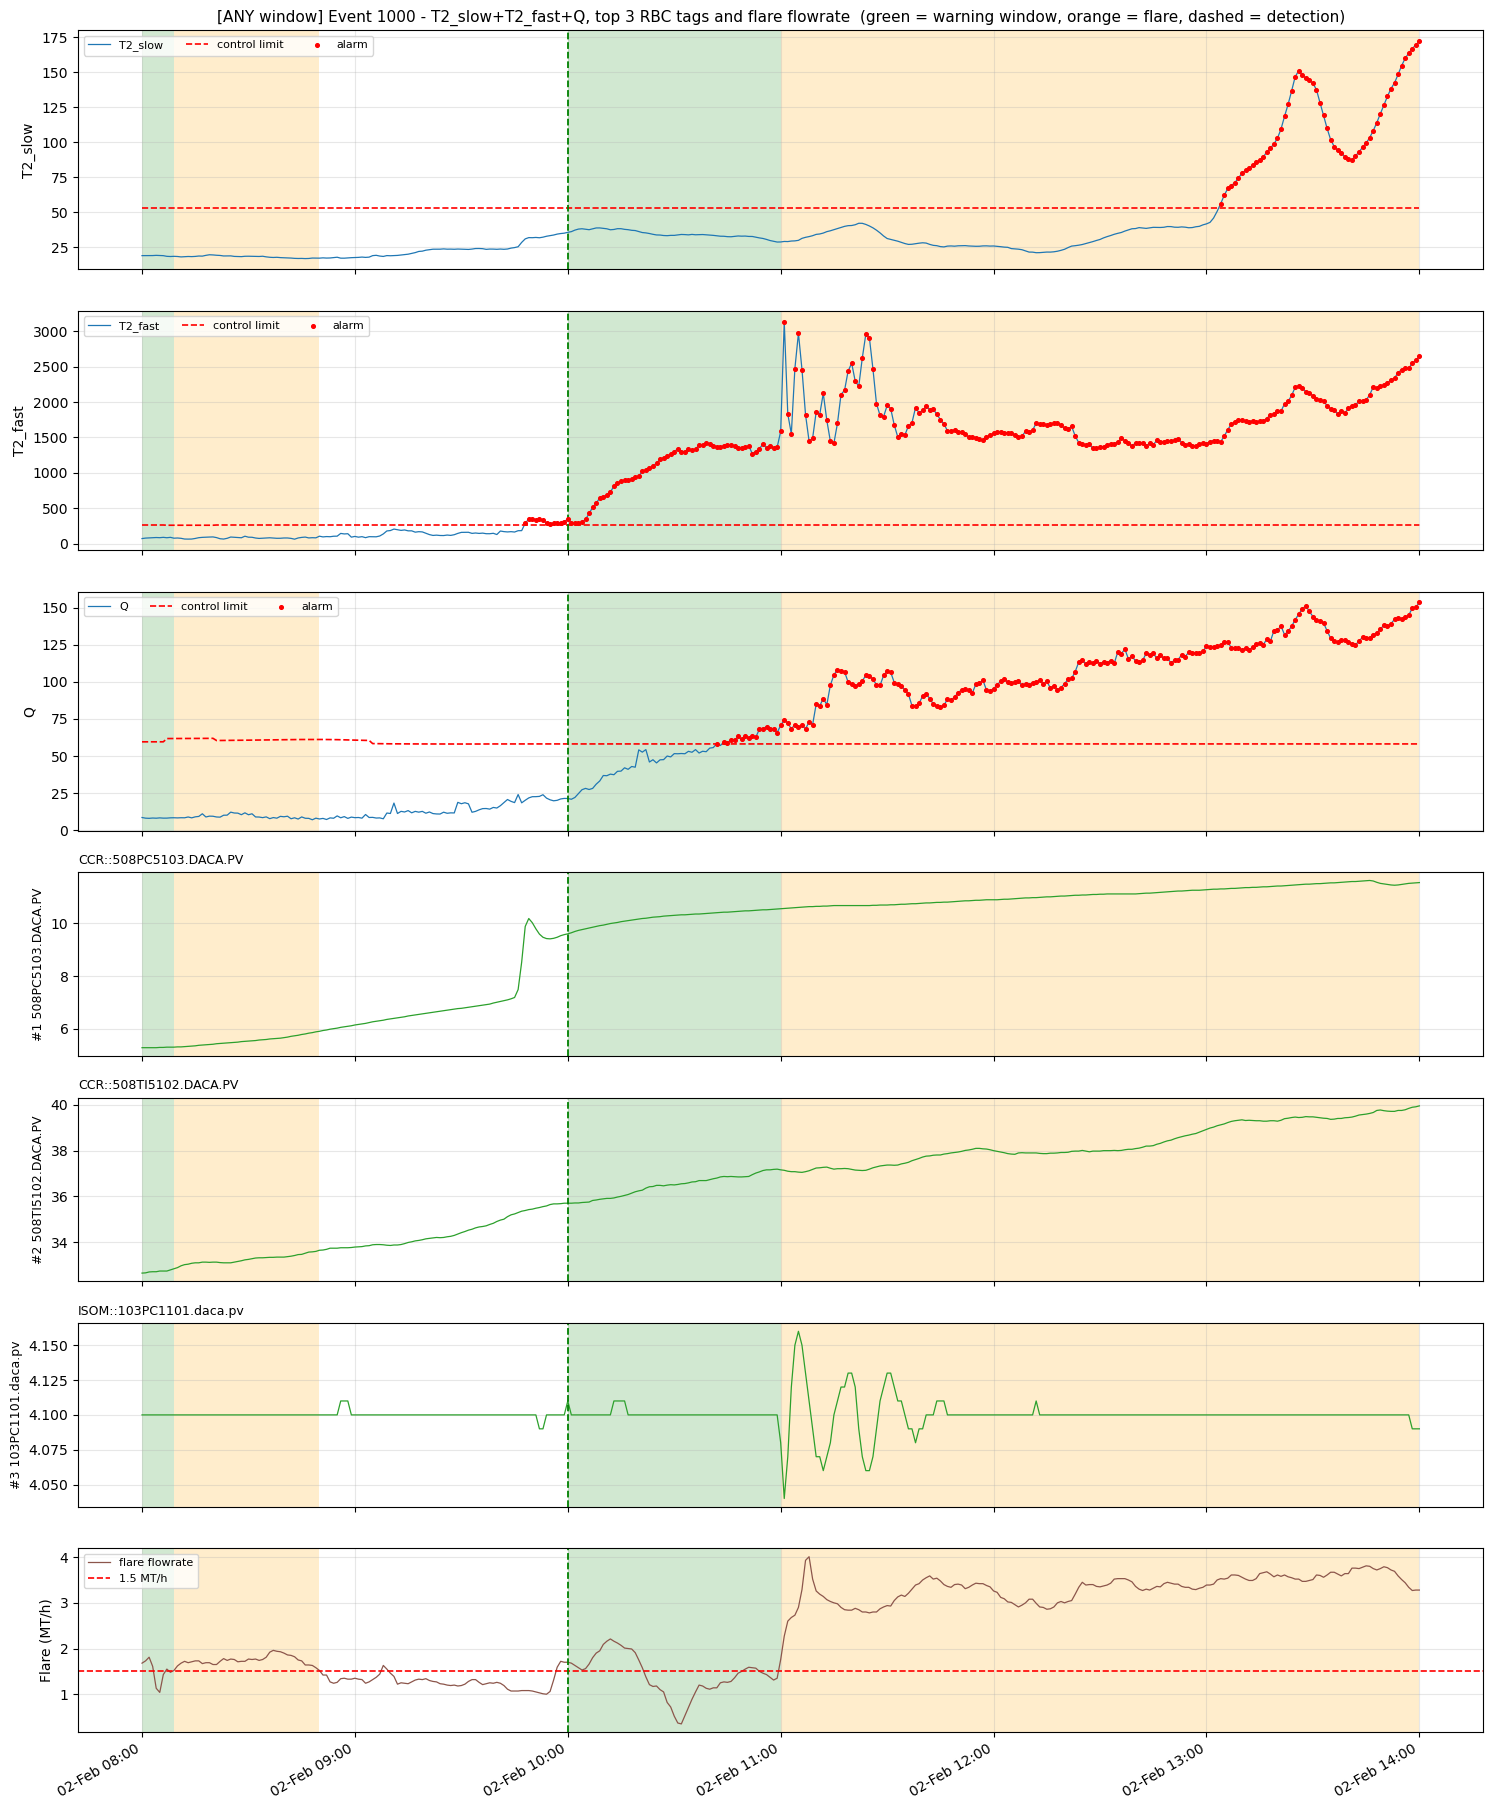

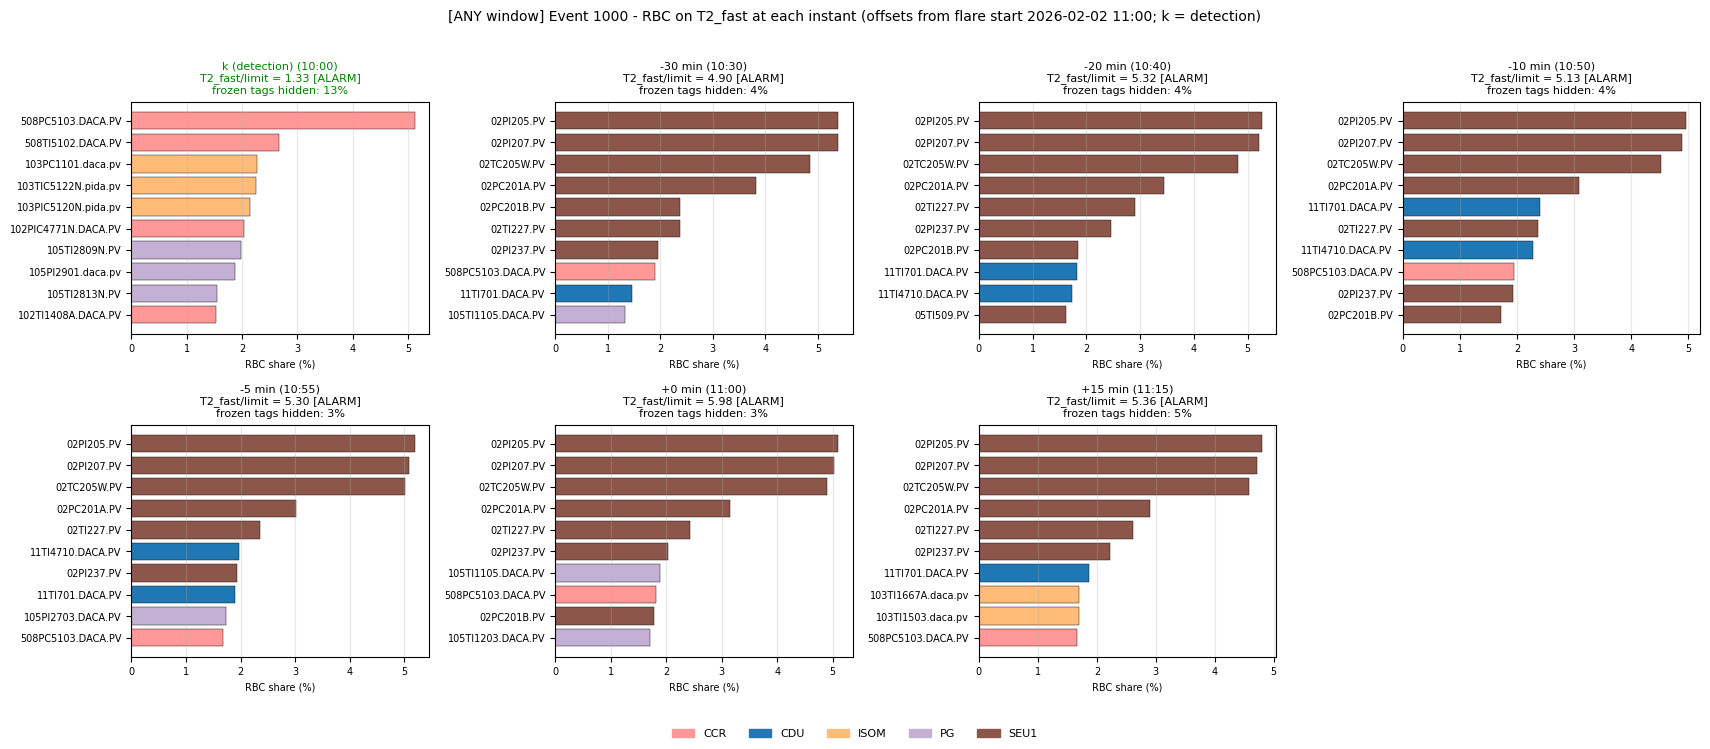

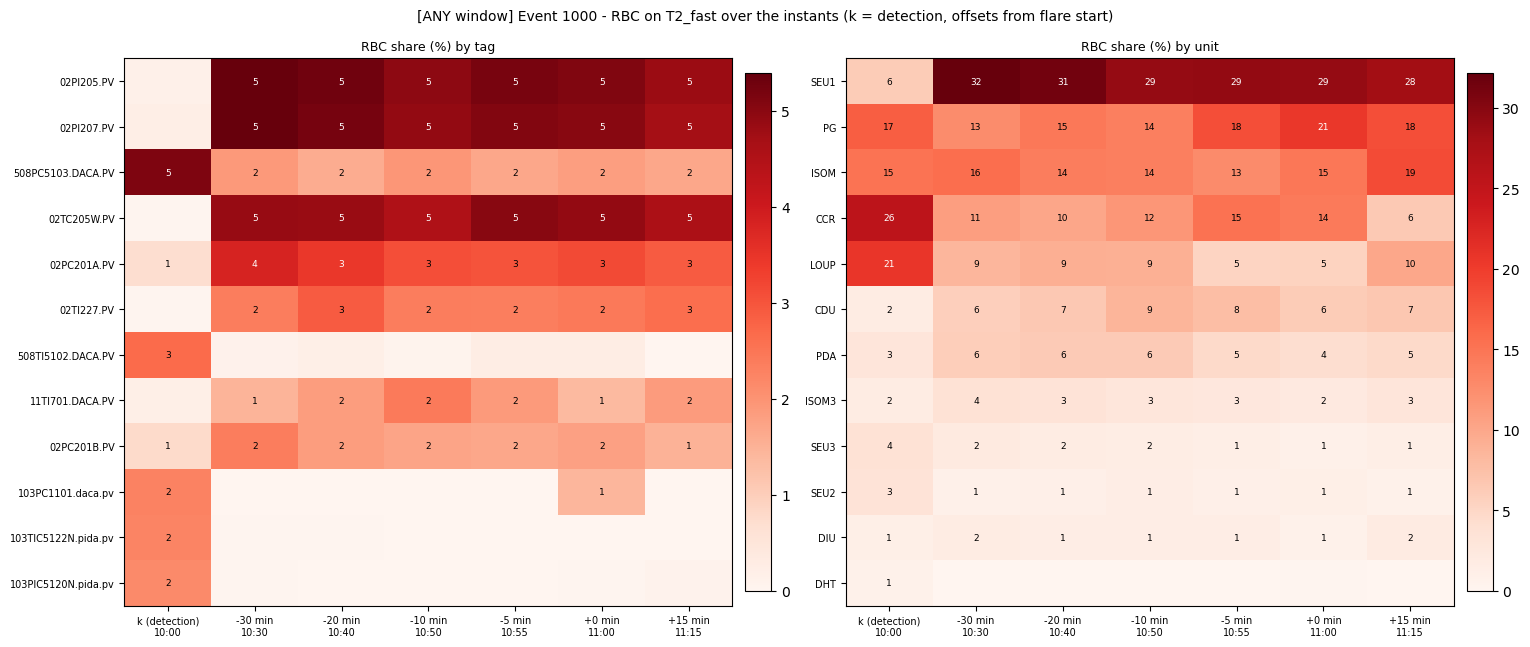

                           k (detection) @ 10:00  -30 min @ 10:30  -20 min @ 10:40  -10 min @ 10:50  -5 min @ 10:55  +0 min @ 11:00  +15 min @ 11:15
tag                                                                                                                                                 
SEU1::02PI205.PV                             0.2              5.4              5.3              5.0             5.2             5.1              4.8
SEU1::02PI207.PV                             0.2              5.4              5.2              4.9             5.1             5.0              4.7
CCR::508PC5103.DACA.PV                       5.1              1.9              1.6              1.9             1.7             1.8              1.7
SEU1::02TC205W.PV                            0.0              4.8              4.8              4.5             5.0             4.9              4.6
SEU1::02PC201A.PV                            0.7              3.8              3.5              3.1       

In [ ]:
# EV : event_id(s) to plot. None -> the N_TOP detected events with the highest
#      peak flow; 5 -> event 5; [5, 12] -> these events
EV = 1000
N_TOP = 2
MY_TAGS = None       # None -> the event's own top-3 RBC tags (RBC on the run's statistic); or a list
HOURS = 3            # plot window: flare start +/- HOURS
# the plots are drawn for every run in PLOT_RULES (settings); e.g. PLOT_RULES = ("ANY",)


def event_ids(EV):
    if EV is None:
        return list(event_df[event_df.detected]
                    .sort_values("peak_flow", ascending=False).event_id.head(N_TOP))
    return [EV] if np.isscalar(EV) else list(EV)

def shade_event(axes, start, end):
    """Warning windows (green), flares (orange), detection instants (dashed)."""
    ev = event_df[(event_df.event_end >= start) & (event_df.event_start <= end)]
    wv = windows[windows.usable & (windows.w_end >= start) & (windows.w_start <= end)]
    for ax in axes:
        ax.grid(alpha=0.3)
        for w in wv.itertuples(index=False):
            ax.axvspan(max(w.w_start, start), min(w.w_end, end), color="green", alpha=0.18, lw=0)
        for e in ev.itertuples(index=False):
            ax.axvspan(max(e.event_start, start), min(e.event_end, end), color="orange", alpha=0.2, lw=0)
            if e.detected and start <= e.detection_time <= end:
                ax.axvline(e.detection_time, color="green", ls="--", lw=1.3)
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d-%b %H:%M"))
    axes[-1].figure.autofmt_xdate(rotation=30)


# ---- (i) run statistic(s) + top RBC tags + flare flowrate, one time axis ------
def plot_event_stat_tags_flare(eid, start, end, tags, savepath=None):
    """Only the statistic(s) of the active run (RUN_STATS: T2_slow for the T2_slow
    window, ...; all three for ANY), then the top RBC tags, then the flare flow."""
    tags = [resolve_tag(t) for t in tags]
    s = stats_df[(stats_df[TS] >= start) & (stats_df[TS] <= end)]
    a = All_df[(All_df[TS] >= start) & (All_df[TS] <= end)]
    f = flare_df[(flare_df[TS] >= start) & (flare_df[TS] <= end)]
    n = len(RUN_STATS) + len(tags) + 1
    fig, axes = plt.subplots(n, 1, figsize=(15, 2.6 * n), sharex=True,
                             gridspec_kw={"height_ratios": [1.3] * len(RUN_STATS) + [1] * (n - len(RUN_STATS))})
    axes = np.atleast_1d(axes)
    for ax, key in zip(axes, RUN_STATS):
        v, lim = s[key].to_numpy(), s[f"{key}_limit"].to_numpy()
        ax.plot(s[TS], v, lw=0.9, label=key)
        ax.plot(s[TS], lim, "r--", lw=1.2, label="control limit")
        exc = v >= lim
        ax.scatter(s[TS][exc], v[exc], s=7, c="red", zorder=3, label="alarm")
        ax.set_ylabel(key)
        ax.legend(loc="upper left", fontsize=8, ncol=3)
    for i, (ax, tag) in enumerate(zip(axes[len(RUN_STATS):], tags), 1):
        ax.plot(a[TS], a[tag], lw=0.9, color="#2ca02c")
        ax.set_ylabel(f"#{i} " + tag.split("::")[-1], fontsize=9)
        ax.set_title(tag, fontsize=9, loc="left")
    axes[-1].plot(f[TS], f[FLOW], lw=0.9, color="#8c564b", label="flare flowrate")
    axes[-1].axhline(THRESHOLD, color="red", ls="--", lw=1.2, label=f"{THRESHOLD} MT/h")
    axes[-1].set_ylabel("Flare (MT/h)")
    axes[-1].legend(loc="upper left", fontsize=8)
    shade_event(axes, start, end)
    axes[0].set_title(f"[{ACTIVE_RULE} window] Event {eid} - {'+'.join(RUN_STATS)}, top {len(tags)} "
                      f"RBC tags and flare flowrate  (green = warning window, orange = flare, "
                      f"dashed = detection)", fontsize=11)
    fig.tight_layout()
    if savepath:
        fig.savefig(savepath, dpi=200, bbox_inches="tight")
    return fig


def rbc_instant_tables(eid):
    """Snapshots of this event on its detection statistic, in time order."""
    stat = detection_stat(eid)
    sn = snaps[(snaps.event_id == eid) & (snaps.stat == stat)]
    sn = sn.sort_values(["offset_min", "is_k"]).reset_index(drop=True)
    return stat, sn, [snapshot_tables(r) for r in sn.itertuples(index=False)]


# ---- (ii) RBC bar chart at every instant -----------------------------------
def plot_rbc_bars(eid, top=10, savepath=None):
    stat, sn, tabs = rbc_instant_tables(eid)
    ucol = {u: plt.get_cmap("tab20")(i % 20) for i, u in enumerate(unit_names)}
    nc = min(4, len(sn))
    nr = int(np.ceil(len(sn) / nc))
    fig, axs = plt.subplots(nr, nc, figsize=(4.3 * nc, 3.3 * nr + 0.9), squeeze=False)
    for ax in axs.ravel()[len(sn):]:
        ax.axis("off")
    for ax, r, (tag, unit, fp) in zip(axs.ravel(), sn.itertuples(index=False), tabs):
        d = tag.head(top).iloc[::-1]
        ax.barh(range(len(d)), d.pct, color=[ucol[u] for u in d.unit], edgecolor="black", lw=0.3)
        ax.set_yticks(range(len(d)))
        ax.set_yticklabels([t.split("::")[-1] for t in d.tag], fontsize=7)
        ax.tick_params(axis="x", labelsize=7)
        ax.set_xlabel("RBC share (%)", fontsize=7)
        ax.grid(axis="x", alpha=0.3)
        ttl = (f"{r.label} ({r.time:%H:%M})\n{stat}/limit = {r.ratio:.2f} "
               f"[{'ALARM' if r.ratio >= 1 else 'no alarm'}]")
        if fp > 1:
            ttl += f"\nfrozen tags hidden: {fp:.0f}%"
        ax.set_title(ttl, fontsize=8, color="green" if r.is_k else "black")
    used = sorted({u for tag, _, _ in tabs for u in tag.head(top).unit})
    fig.legend(handles=[Patch(color=ucol[u], label=u) for u in used], loc="lower center",
               ncol=min(len(used), 8), fontsize=8, frameon=False)
    start = events.set_index("event_id").loc[eid, "start"]
    fig.suptitle(f"[{ACTIVE_RULE} window] Event {eid} - RBC on {stat} at each instant "
                 f"(offsets from flare start {start:%Y-%m-%d %H:%M}; k = detection)", fontsize=10)
    fig.tight_layout(rect=(0, 0.05, 1, 0.97))
    if savepath:
        fig.savefig(savepath, dpi=200, bbox_inches="tight")
    return fig


# ---- (iii) heat maps: tags and units over the instants -----------------------
def plot_rbc_heatmaps(eid, heat_top=15, savepath=None):
    stat, sn, tabs = rbc_instant_tables(eid)
    cols = [f"{r.label}\n{r.time:%H:%M}" for r in sn.itertuples(index=False)]
    best = {}
    for tag, _, _ in tabs:
        for t, p in zip(tag.tag.head(5), tag.pct.head(5)):
            best[t] = max(best.get(t, 0), p)
    heat = sorted(best, key=best.get, reverse=True)[:heat_top]
    tag_mat = pd.DataFrame({c: t.set_index("tag").pct.reindex(heat)
                            for c, (t, _, _) in zip(cols, tabs)})
    unit_mat = pd.DataFrame({c: u for c, (_, u, _) in zip(cols, tabs)}).fillna(0)
    unit_mat = unit_mat.loc[unit_mat.mean(1).sort_values(ascending=False).index]
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(max(12, 1.2 * len(cols) + 7),
                                                0.38 * max(len(tag_mat), 8) + 2))
    for ax, mat, name in ((a1, tag_mat, "tag"), (a2, unit_mat, "unit")):
        vals = mat.to_numpy(float)
        im = ax.imshow(np.nan_to_num(vals), aspect="auto", cmap="Reds", vmin=0)
        ax.set_xticks(range(mat.shape[1]))
        ax.set_xticklabels(mat.columns, fontsize=7)
        ax.set_yticks(range(mat.shape[0]))
        ax.set_yticklabels([str(x).split("::")[-1] for x in mat.index], fontsize=7)
        for (y, x), v in np.ndenumerate(vals):
            if v == v and v >= 0.5:
                ax.text(x, y, f"{v:.0f}", ha="center", va="center", fontsize=6.5,
                        color="white" if v > 0.6 * np.nanmax(vals) else "black")
        ax.set_title(f"RBC share (%) by {name}", fontsize=9)
        fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
    fig.suptitle(f"[{ACTIVE_RULE} window] Event {eid} - RBC on {stat} over the instants "
                 f"(k = detection, offsets from flare start)", fontsize=10)
    fig.tight_layout()
    if savepath:
        fig.savefig(savepath, dpi=200, bbox_inches="tight")
    return fig, tag_mat, unit_mat


lbl = lambda c: c.replace("\n", " @ ")

for rule in PLOT_RULES:
    use_run(rule)
    print("#" * 90)
    print(f"MOVING WINDOW [{rule}]  hold on {' OR '.join(FREEZE_ON)}")
    for eid in event_ids(EV):
        eid = int(eid)
        if eid not in set(event_df.event_id):
            print(f"event {eid} does not exist - valid ids {event_df.event_id.min()}..{event_df.event_id.max()}")
            continue
        row = event_df.set_index("event_id").loc[eid]
        if MY_TAGS:
            tags = list(MY_TAGS)
        elif eid in event_rbc:
            t = event_rbc[eid]["tags"]
            tags = list(t[~t.flat].tag.head(3))
        else:
            tags = []
        start = row.event_start - pd.Timedelta(hours=HOURS)
        end = row.event_start + pd.Timedelta(hours=HOURS)
        print("=" * 78)
        print(f"[{rule}] EVENT {eid}  start {row.event_start:%Y-%m-%d %H:%M}  peak {row.peak_flow:.2f} MT/h  "
              + (f"detected {row.lead_min:.0f} min ahead by {row.detection_statistic}"
                 if row.detected else "NOT detected"))
        print(f"tags: {', '.join(tags) or '-'}")

        plot_event_stat_tags_flare(eid, start, end, tags,
                                   savepath=f"{rule}_event{eid}_1_stat_tags_flare.jpeg")   # (i)
        plt.show()
        plot_rbc_bars(eid, savepath=f"{rule}_event{eid}_2_rbc_bars.jpeg")                  # (ii)
        plt.show()
        _, tag_mat, unit_mat = plot_rbc_heatmaps(eid, savepath=f"{rule}_event{eid}_3_rbc_heatmaps.jpeg")  # (iii)
        plt.show()
        print(tag_mat.rename(columns=lbl).round(1).to_string())
        print(unit_mat.rename(columns=lbl).round(1).to_string())

##########################################################################################
[T2_slow window] 807 detected events of 1294 flare events

Top 10 tags (in an event's RBC top 5):
               tag unit  n_events  n_rank1  mean_rbc_pct  pct_of_detected_events
 SEU3::42TI4277.PV SEU3        38       13          2.73                     4.7
   CDU::THTI402.PV  CDU        37       10          2.44                     4.6
 SEU3::42PC4275.PV SEU3        36        8          2.75                     4.5
 SEU1::02TC205W.PV SEU1        35       14          2.47                     4.3
 SEU2::PTI3201A.PV SEU2        35       11          2.41                     4.3
DHT::700py3501b.op  DHT        34       23          4.14                     4.2
  DIU::71PC9101.PV  DIU        34        9          2.88                     4.2
   CDU::17TI115.PV  CDU        34        7          2.67                     4.2
 DIU::71TI9702B.PV  DIU        32        5          2.42                     4.0
 

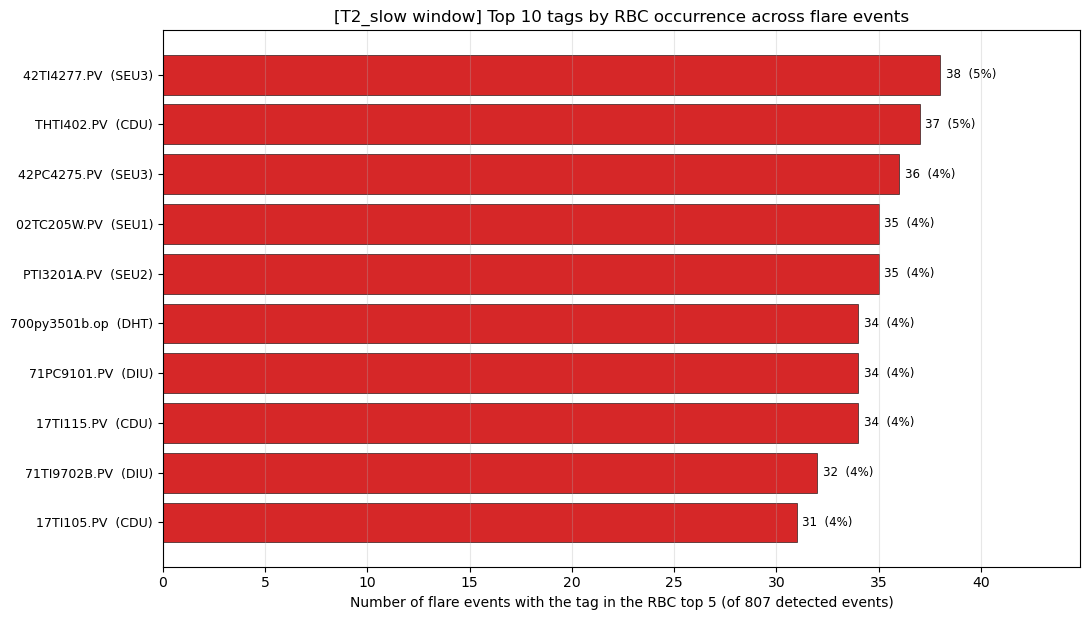


Top 10 units (in an event's RBC top 3):
unit  n_events  n_rank1  mean_rbc_pct  pct_of_detected_events
 CCR       542      179         18.22                    67.2
LOUP       506      275         23.18                    62.7
ISOM       465      137         18.05                    57.6
  PG       327       92         17.40                    40.5
 PDA       247       62         16.33                    30.6
 DIU        94       28         15.52                    11.6
SEU1        76        9         14.26                     9.4
SEU2        60       10         14.22                     7.4
 CDU        40       11         15.39                     5.0
SEU3        35        2         13.58                     4.3


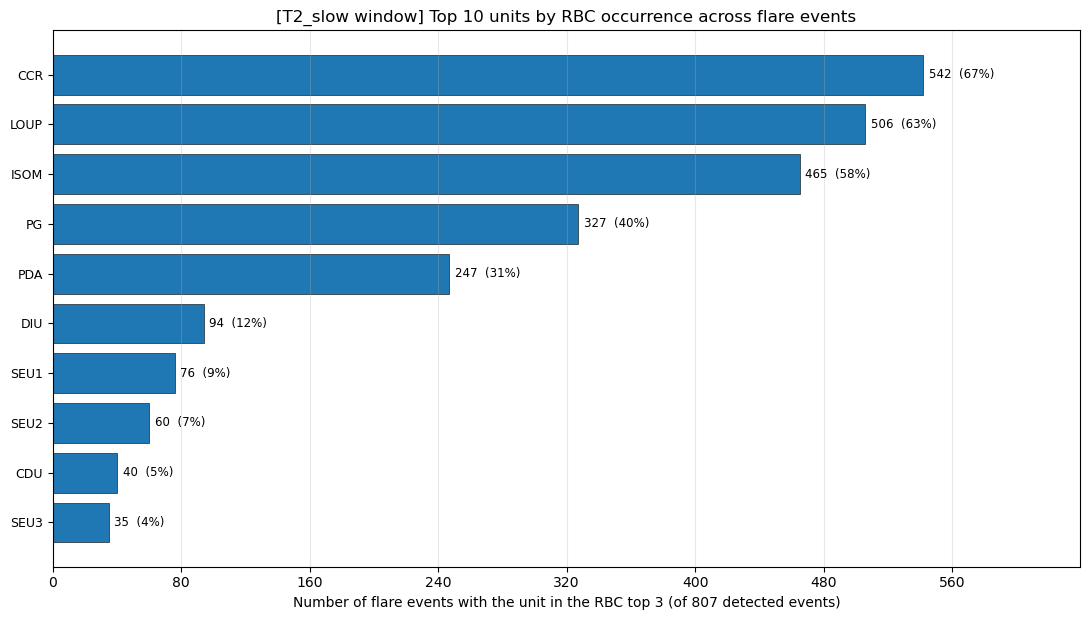

##########################################################################################
[T2_fast window] 962 detected events of 1294 flare events

Top 10 tags (in an event's RBC top 5):
                   tag unit  n_events  n_rank1  mean_rbc_pct  pct_of_detected_events
     SEU3::42TI4277.PV SEU3        45       10          8.09                     4.7
     SEU3::42PC4275.PV SEU3        43       19          8.12                     4.5
     SEU1::02TC205W.PV SEU1        43       24          5.47                     4.5
       CDU::THTI402.PV  CDU        42       12          5.74                     4.4
       CDU::17TI105.PV  CDU        40        9          5.35                     4.2
CCR::508PC5103.DACA.PV  CCR        40       16          4.25                     4.2
      DIU::71PI8703.PV  DIU        36        5          4.03                     3.7
   ISOM::103TI7015N.pv ISOM        35       10          5.00                     3.6
LOUP::99TI3205.DACA.PV LOUP        35        4

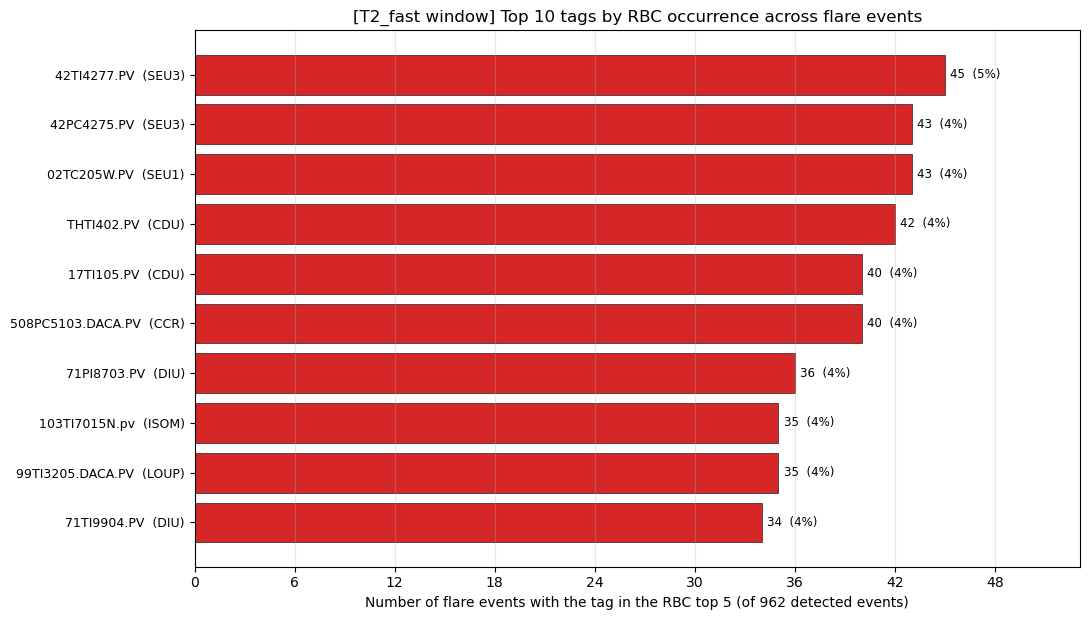


Top 10 units (in an event's RBC top 3):
unit  n_events  n_rank1  mean_rbc_pct  pct_of_detected_events
LOUP       642      281         25.25                    66.7
 CCR       590      197         20.55                    61.3
ISOM       503      146         20.66                    52.3
  PG       349       69         16.90                    36.3
 PDA       268       78         19.22                    27.9
 DIU       139       35         19.70                    14.4
SEU1       110       34         19.49                    11.4
SEU3        94       45         24.82                     9.8
 CDU        81       36         24.40                     8.4
SEU2        59       22         20.83                     6.1


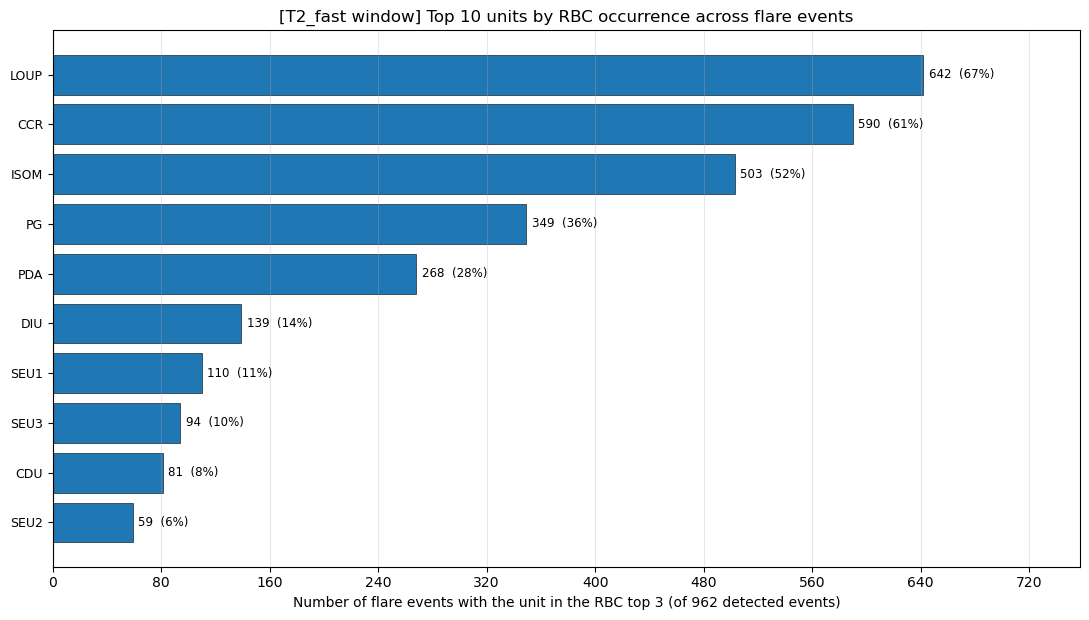

##########################################################################################
[Q window] 619 detected events of 1294 flare events

Top 10 tags (in an event's RBC top 5):
                    tag unit  n_events  n_rank1  mean_rbc_pct  pct_of_detected_events
      SEU1::02TC205W.PV SEU1        41       35         36.91                     6.6
      SEU3::42PI4304.PV SEU3        39        2         11.41                     6.3
ISOM::103TI7003.daca.pv ISOM        38       14         30.85                     6.1
    ISOM::103TI7015N.pv ISOM        36       11         24.51                     5.8
 CCR::508PC5103.DACA.PV  CCR        35        9         19.06                     5.7
    ISOM::103TI5466A.pv ISOM        31        9         15.62                     5.0
 CCR::508PC5104.DACA.PV  CCR        30       14         28.18                     4.8
LOUP::99TI1505A.DACA.PV LOUP        30       12         17.58                     4.8
 LOUP::99TI1607.DACA.PV LOUP        30     

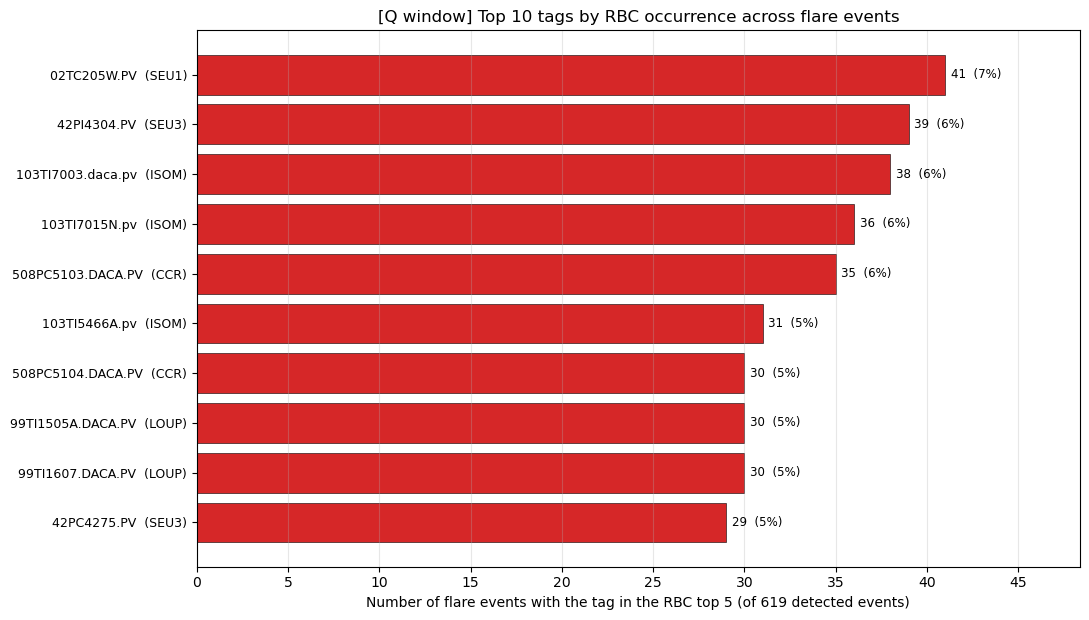


Top 10 units (in an event's RBC top 3):
 unit  n_events  n_rank1  mean_rbc_pct  pct_of_detected_events
 ISOM       311      123         35.76                    50.2
  CCR       304       90         28.54                    49.1
   PG       250       37         14.63                    40.4
 LOUP       227      114         45.33                    36.7
  PDA       168       35         19.11                    27.1
 SEU2       119       19         16.99                    19.2
  DIU       104       43         38.97                    16.8
ISOM3        99       18         15.58                    16.0
 SEU3        97       52         45.61                    15.7
  CDU        91       39         39.55                    14.7


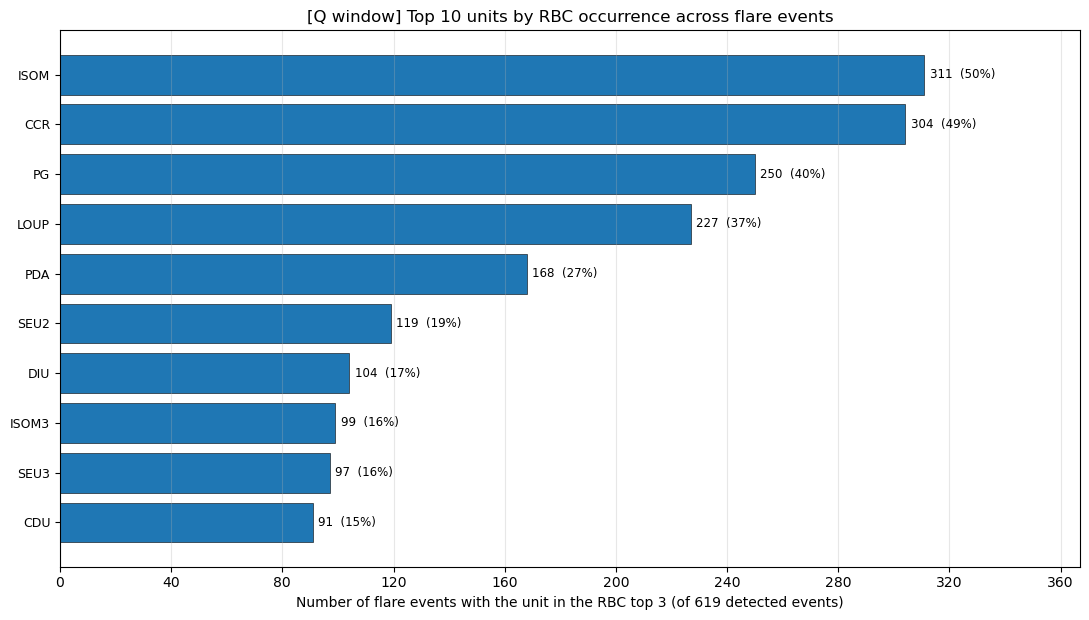

##########################################################################################
[ANY window] 1053 detected events of 1294 flare events

Top 10 tags (in an event's RBC top 5):
                    tag unit  n_events  n_rank1  mean_rbc_pct  pct_of_detected_events
      SEU1::02TC205W.PV SEU1        49       25         15.80                     4.7
    ISOM::103TI7015N.pv ISOM        47       13          9.00                     4.5
      SEU3::42TI4277.PV SEU3        46       10         10.36                     4.4
 CCR::508PC5103.DACA.PV  CCR        44       16         13.70                     4.2
     DHT::700py3501b.op  DHT        44       24          9.71                     4.2
      SEU3::42PC4275.PV SEU3        42       18         12.54                     4.0
ISOM::103TI7003.daca.pv ISOM        40       13         13.57                     3.8
        CDU::17PT101.PV  CDU        39       12         11.66                     3.7
 LOUP::99TI1607.DACA.PV LOUP        39  

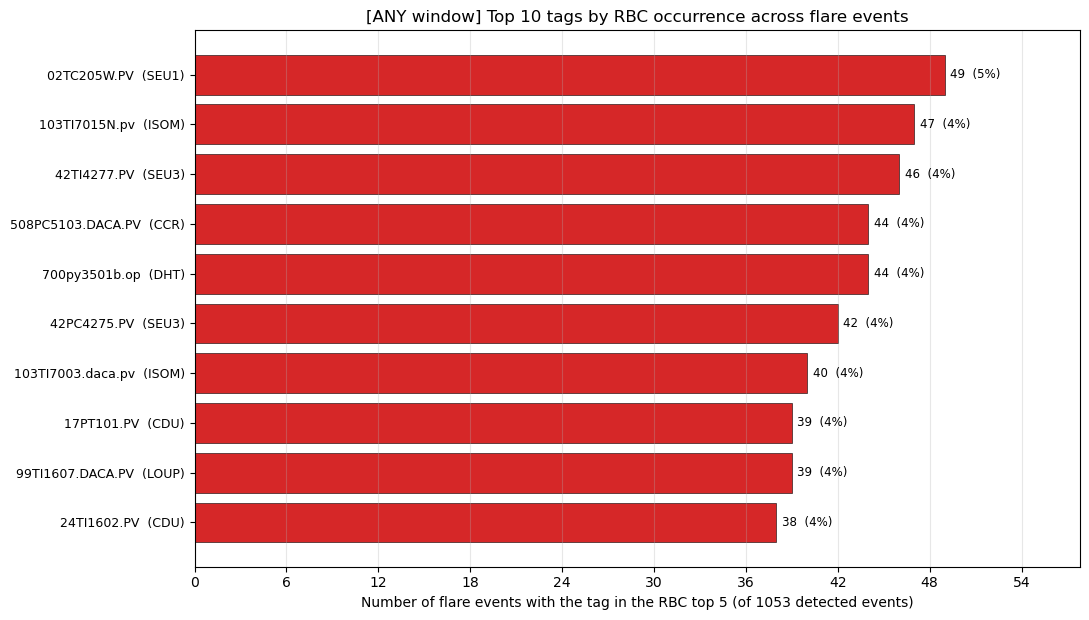


Top 10 units (in an event's RBC top 3):
unit  n_events  n_rank1  mean_rbc_pct  pct_of_detected_events
LOUP       666      313         28.66                    63.2
 CCR       605      201         21.50                    57.5
ISOM       559      178         23.80                    53.1
  PG       401       75         15.26                    38.1
 PDA       319       90         18.50                    30.3
 DIU       136       44         21.00                    12.9
SEU3       107       46         26.17                    10.2
SEU1       101       32         23.70                     9.6
SEU2        96       28         19.80                     9.1
 CDU        90       30         26.51                     8.5


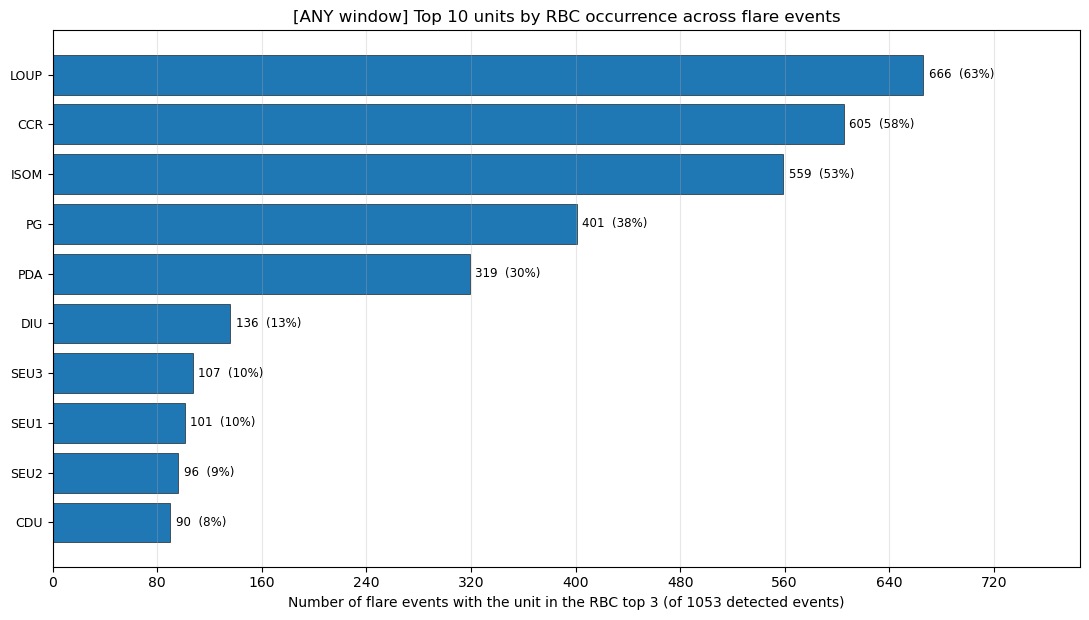

% of detected events with the tag in its RBC top 5, per moving-window run:
                         T2_slow  T2_fast    Q  ANY
tag                                                
SEU1::02TC205W.PV            4.3      4.5  6.6  4.7
SEU3::42TI4277.PV            4.7      4.7  4.4  4.4
SEU3::42PC4275.PV            4.5      4.5  4.7  4.0
ISOM::103TI7015N.pv          3.7      3.6  5.8  4.5
CCR::508PC5103.DACA.PV       2.5      4.2  5.7  4.2
ISOM::103TI7003.daca.pv      3.5      2.8  6.1  3.8
CDU::THTI402.PV              4.6      4.4  3.2  3.5
SEU2::PTI3201A.PV            4.3      2.1  4.7  3.5
LOUP::99TI1407.DACA.PV       3.2      2.8  4.7  3.1
SEU3::42PI4304.PV            1.1      2.8  6.3  3.5


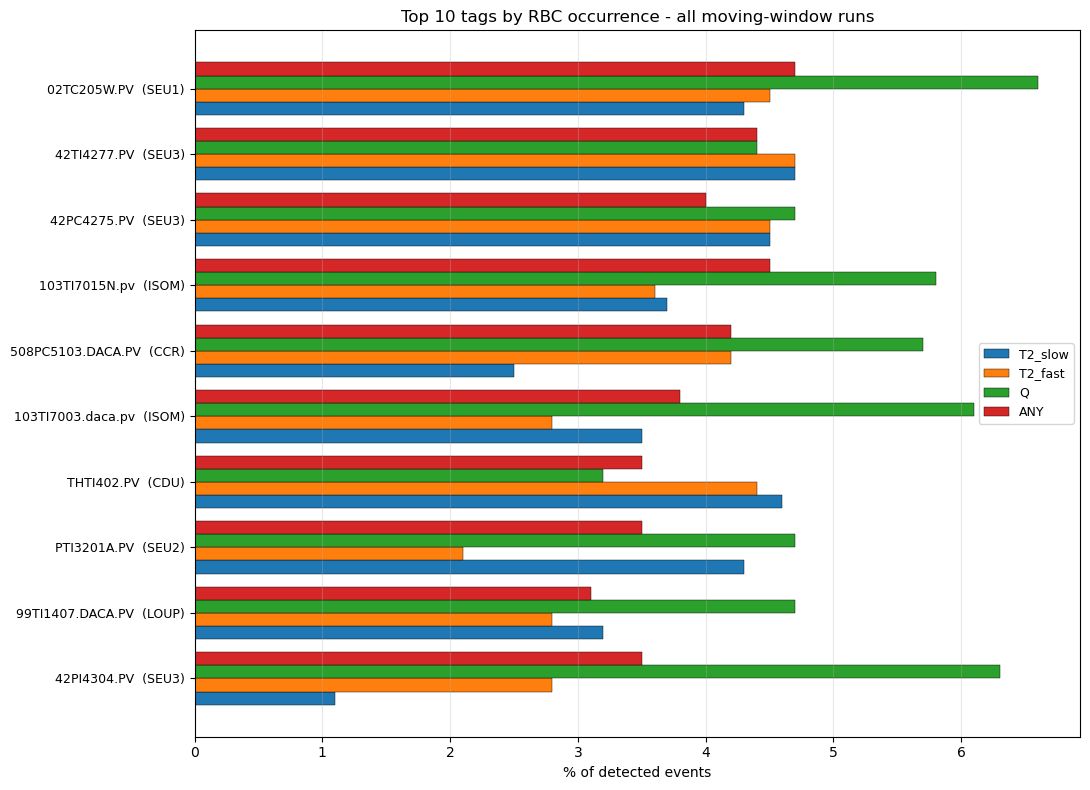

% of detected events with the unit in its RBC top 3, per moving-window run:
      T2_slow  T2_fast     Q   ANY
unit                              
CCR      67.2     61.3  49.1  57.5
LOUP     62.7     66.7  36.7  63.2
ISOM     57.6     52.3  50.2  53.1
PG       40.5     36.3  40.4  38.1
PDA      30.6     27.9  27.1  30.3
DIU      11.6     14.4  16.8  12.9
SEU1      9.4     11.4  12.1   9.6
SEU2      7.4      6.1  19.2   9.1
SEU3      4.3      9.8  15.7  10.2
CDU       5.0      8.4  14.7   8.5


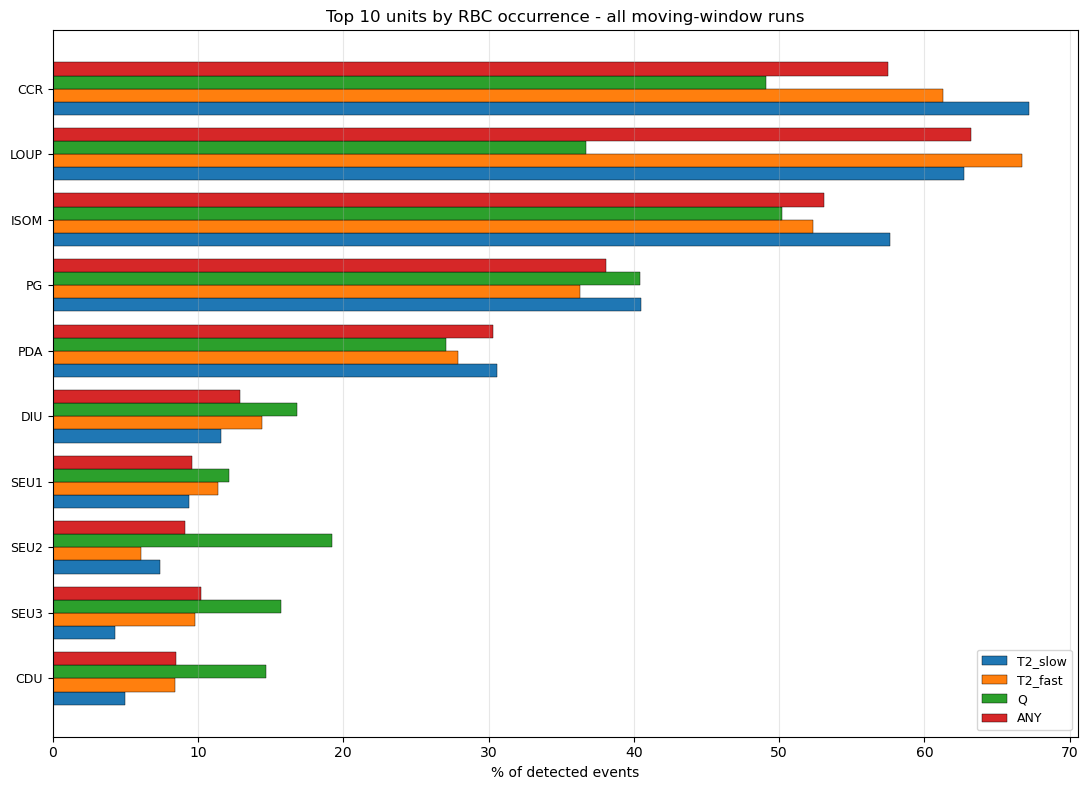

In [ ]:
TOP_K_TAGS = 5      # a tag counts for an event if it is in that event's top 5
TOP_K_UNITS = 3     # a unit counts for an event if it is in that event's top 3
N_SHOW = 10         # bars in each chart


def rbc_frequency(level, top_k):
    """How many detected events have each tag / unit in their top_k RBC."""
    rows = []
    for eid, h in event_rbc.items():
        if level == "tag":
            t = h["tags"][~h["tags"].flat].head(top_k)
            names, pcts, units = t.tag, t.contrib_pct, t.unit
        else:
            t = h["units"].head(top_k)
            names, pcts, units = t.unit, t.contrib_pct, t.unit
        for rank, (n, p, u) in enumerate(zip(names, pcts, units), 1):
            rows.append({level: n, "unit": u, "event_id": eid, "rank": rank, "pct": p})
    long = pd.DataFrame(rows)
    n_det = len(event_rbc)
    agg = {"n_events": ("event_id", "nunique"),
           "n_rank1": ("rank", lambda r: int((r == 1).sum())),
           "mean_rbc_pct": ("pct", "mean")}
    if level == "tag":
        agg = {"unit": ("unit", "first"), **agg}
    freq = (long.groupby(level).agg(**agg)
            .sort_values(["n_events", "mean_rbc_pct"], ascending=False)
            .reset_index())
    freq["pct_of_detected_events"] = (100 * freq.n_events / n_det).round(1)
    freq["mean_rbc_pct"] = freq.mean_rbc_pct.round(2)
    return freq


def plot_frequency(freq, level, top_k, color, savepath):
    d = freq.head(N_SHOW).iloc[::-1]
    n_det = len(event_rbc)
    fig, ax = plt.subplots(figsize=(11, 0.45 * len(d) + 1.8))
    bars = ax.barh(range(len(d)), d.n_events, color=color, edgecolor="black", lw=0.4)
    ax.set_yticks(range(len(d)))
    ax.set_yticklabels([str(n).split("::")[-1] + (f"  ({n.split('::')[0]})" if "::" in str(n) else "")
                        for n in d[level]], fontsize=9)
    for b, n, p in zip(bars, d.n_events, d.pct_of_detected_events):
        ax.annotate(f"{n}  ({p:.0f}%)", (b.get_width(), b.get_y() + b.get_height() / 2),
                    xytext=(4, 0), textcoords="offset points", va="center", fontsize=8.5)
    ax.set_xlabel(f"Number of flare events with the {level} in the RBC top {top_k} "
                  f"(of {n_det} detected events)")
    ax.set_xlim(0, max(d.n_events.max() * 1.18, 1))
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.set_title(f"[{ACTIVE_RULE} window] Top {len(d)} {level}s by RBC occurrence across flare events")
    ax.grid(axis="x", alpha=0.3)
    fig.tight_layout()
    fig.savefig(savepath, dpi=200, bbox_inches="tight")
    return fig



# ---- RBC frequency for every moving-window run -------------------------------
freq_tabs = {"tag": {}, "unit": {}}
for rule in RUNS:
    use_run(rule)
    print("#" * 90)
    if not event_rbc:
        print(f"[{rule} window] no detected events - nothing to summarise")
        continue
    print(f"[{rule} window] {len(event_rbc)} detected events of {len(events)} flare events\n")

    # ---- (1) tags ----
    tag_freq = rbc_frequency("tag", TOP_K_TAGS)
    freq_tabs["tag"][rule] = tag_freq
    print(f"Top {N_SHOW} tags (in an event's RBC top {TOP_K_TAGS}):")
    print(tag_freq.head(N_SHOW).to_string(index=False))
    tag_freq.to_csv(f"rbc_tag_frequency_{rule}.csv", index=False)
    plot_frequency(tag_freq, "tag", TOP_K_TAGS, "#d62728", f"rbc_top10_tags_{rule}.jpeg")
    plt.show()

    # ---- (2) units ----
    unit_freq = rbc_frequency("unit", TOP_K_UNITS)
    freq_tabs["unit"][rule] = unit_freq
    print(f"\nTop {N_SHOW} units (in an event's RBC top {TOP_K_UNITS}):")
    print(unit_freq.head(N_SHOW).to_string(index=False))
    unit_freq.to_csv(f"rbc_unit_frequency_{rule}.csv", index=False)
    plot_frequency(unit_freq, "unit", TOP_K_UNITS, "#1f77b4", f"rbc_top10_units_{rule}.jpeg")
    plt.show()

# ---- side by side: % of detected events with the tag / unit in its top k -----
for level in ("tag", "unit"):
    tabs = freq_tabs[level]
    if not tabs:
        continue
    wide = pd.concat({r: t.set_index(level)["pct_of_detected_events"] for r, t in tabs.items()},
                     axis=1).fillna(0)
    wide = wide.loc[wide.mean(1).sort_values(ascending=False).index]
    wide.to_csv(f"rbc_{level}_frequency_all_windows.csv")
    print("=" * 90)
    print(f"% of detected events with the {level} in its RBC top "
          f"{TOP_K_TAGS if level == 'tag' else TOP_K_UNITS}, per moving-window run:")
    print(wide.head(N_SHOW).round(1).to_string())

    d = wide.head(N_SHOW).iloc[::-1]
    h = 0.8 / d.shape[1]
    fig, ax = plt.subplots(figsize=(11, 0.6 * len(d) + 2))
    for i, rule in enumerate(d.columns):
        ax.barh(np.arange(len(d)) - 0.4 + h * (i + 0.5), d[rule], h, edgecolor="black",
                lw=0.3, label=rule)
    ax.set_yticks(range(len(d)))
    ax.set_yticklabels([str(n).split("::")[-1] + (f"  ({n.split('::')[0]})" if "::" in str(n) else "")
                        for n in d.index], fontsize=9)
    ax.set_xlabel("% of detected events")
    ax.set_title(f"Top {len(d)} {level}s by RBC occurrence - all moving-window runs")
    ax.legend(fontsize=9)
    ax.grid(axis="x", alpha=0.3)
    fig.tight_layout()
    fig.savefig(f"rbc_top10_{level}s_all_windows.jpeg", dpi=200, bbox_inches="tight")
    plt.show()